## Data set Link
https://www.kaggle.com/datasets/nanditapore/credit-risk-analysis

## Dataset Overview

This dataset represents loan applications from individuals, including demographic, financial, and credit-related features. The objective is to predict whether a person will default on a loan based on these characteristics.

The data contains a mix of:

Numerical features (e.g., income, loan amount)

Categorical features (e.g., intent, home ownership)

Binary target variable: default (yes/no → 0

## Column Descriptions

| Column Name              | Description                                                                 |
|--------------------------|-----------------------------------------------------------------------------|
| `age`                    | Age of the applicant in years                                               |
| `income`                 | Annual income of the applicant                                              |
| `home`                   | Home ownership status (`RENT`, `OWN`, `MORTGAGE`, `OTHER`)                  |
| `emp_length`             | Employment length in years                                                  |
| `amount`                 | Loan amount requested                                                       |
| `intent`                 | Purpose of the loan (`EDUCATION`, `MEDICAL`, `VENTURE`, etc.)               |
| `rate`                   | Interest rate charged on the loan                                           |
| `status`                 | Loan status (`0` for not defaulted, `1` for defaulted)                      |
| `percent_income`         | Portion of income used to repay the loan (ratio of amount to income)        |
| `cred_length`            | Length of the applicant's credit history in years                           |
| `default`                | **Target variable**: Whether the applicant defaulted (`0` = yes, `1` = no)  |

# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import missingno as msno
from scipy import stats
from scipy.stats import f_oneway
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import RFE
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Create a color palette object
colors = sns.color_palette("RdBu", 6)

# Apply theme and colors to Seaborn
sns.set_theme(style="whitegrid", palette=colors, font="sans-serif")


# LOADING DATASET

### Import dataset using Pandas

In [ ]:
df = pd.read_csv('credit_risk.csv')

# DATA INSPECTION

### Checking the shape of the Dataset

In [4]:
print(df.shape)
df.head()

(32581, 12)


,Id,Age,Income,Home,Emp_length,Intent,Amount,Rate,Status,Percent_income,Default,Cred_length
0,0,22,59000,RENT,123.0,PERSONAL,35000,16.02,1,0.59,Y,3
1,1,21,9600,OWN,5.0,EDUCATION,1000,11.14,0,0.10,N,2
2,2,25,9600,MORTGAGE,1.0,MEDICAL,5500,12.87,1,0.57,N,3
3,3,23,65500,RENT,4.0,MEDICAL,35000,15.23,1,0.53,N,2
4,4,24,54400,RENT,8.0,MEDICAL,35000,14.27,1,0.55,Y,4


### Checking the Columns in the Datase

In [5]:
df.columns

Index(['Id', 'Age', 'Income', 'Home', 'Emp_length', 'Intent', 'Amount', 'Rate',
       'Status', 'Percent_income', 'Default', 'Cred_length'],
      dtype='object')

In [6]:
df.columns=df.columns.str.lower()
df.columns

Index(['id', 'age', 'income', 'home', 'emp_length', 'intent', 'amount', 'rate',
       'status', 'percent_income', 'default', 'cred_length'],
      dtype='object')

### Information about the Dataset

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              32581 non-null  int64  
 1   age             32581 non-null  int64  
 2   income          32581 non-null  int64  
 3   home            32581 non-null  object 
 4   emp_length      31686 non-null  float64
 5   intent          32581 non-null  object 
 6   amount          32581 non-null  int64  
 7   rate            29465 non-null  float64
 8   status          32581 non-null  int64  
 9   percent_income  32581 non-null  float64
 10  default         32581 non-null  object 
 11  cred_length     32581 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 3.0+ MB


In [8]:
df.describe()

,id,age,income,emp_length,amount,rate,status,percent_income,cred_length
count,32581.000000,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,16290.006139,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,9405.479594,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,0.000000,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,8145.000000,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,16290.000000,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,24435.000000,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,32780.000000,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


### Remove not important feature

In [9]:
df = df.drop('id', axis=1)

### split cols into numerical and categorical features

In [10]:
num_cols = list(df.select_dtypes(include='number').columns)
cat_cols =  list(df.select_dtypes(include='object').columns)

print(num_cols)
print(cat_cols)

['age', 'income', 'emp_length', 'amount', 'rate', 'status', 'percent_income', 'cred_length']
['home', 'intent', 'default']


### Show each value in categorical features to check its consistensy

In [11]:
for i in cat_cols:
 print(df[i].value_counts())

home
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64
intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64
default
N    26836
Y     5745
Name: count, dtype: int64


# Data Cleaning

### Checking if there are any null values present in the dataset

In [12]:
# Check total missing values per column
print(df.isnull().sum())

# Check percentage of missing values per column
print((df.isnull().sum() / len(df)) * 100)

age                  0
income               0
home                 0
emp_length         895
intent               0
amount               0
rate              3116
status               0
percent_income       0
default              0
cred_length          0
dtype: int64
age               0.000000
income            0.000000
home              0.000000
emp_length        2.747000
intent            0.000000
amount            0.000000
rate              9.563856
status            0.000000
percent_income    0.000000
default           0.000000
cred_length       0.000000
dtype: float64


### Missing Values per Column
Shows the proportion of missing values for each variable, with most variables having missingness rates , while "rate" appears to have somewhat less missingness

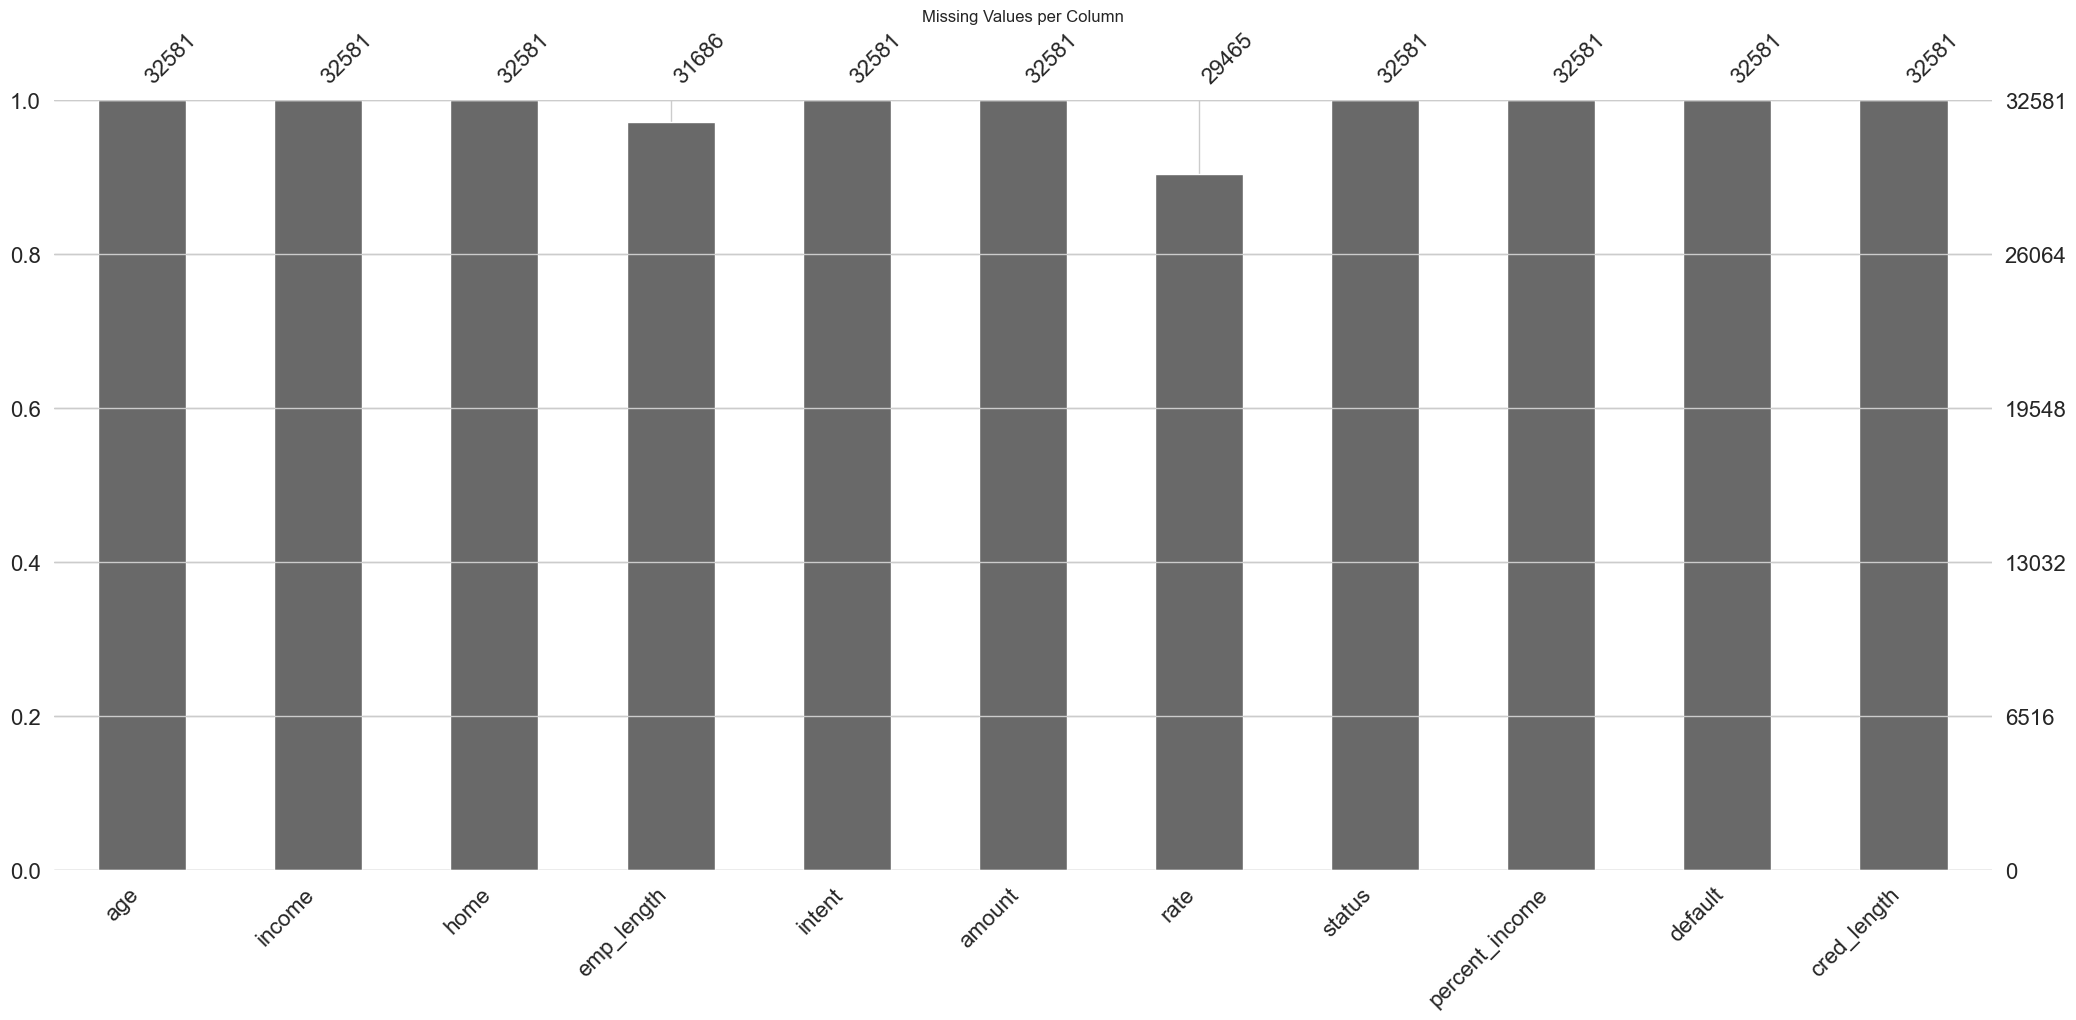

In [13]:
msno.bar(df)
plt.title("Missing Values per Column")
plt.show()


 ### Missing Data Matrix 
 Shows the pattern of missing values across all variables and observations. The light areas represent missing values, and there are clear patterns visible - particularly  missingness in certain columns like "emp_length" and "rate".

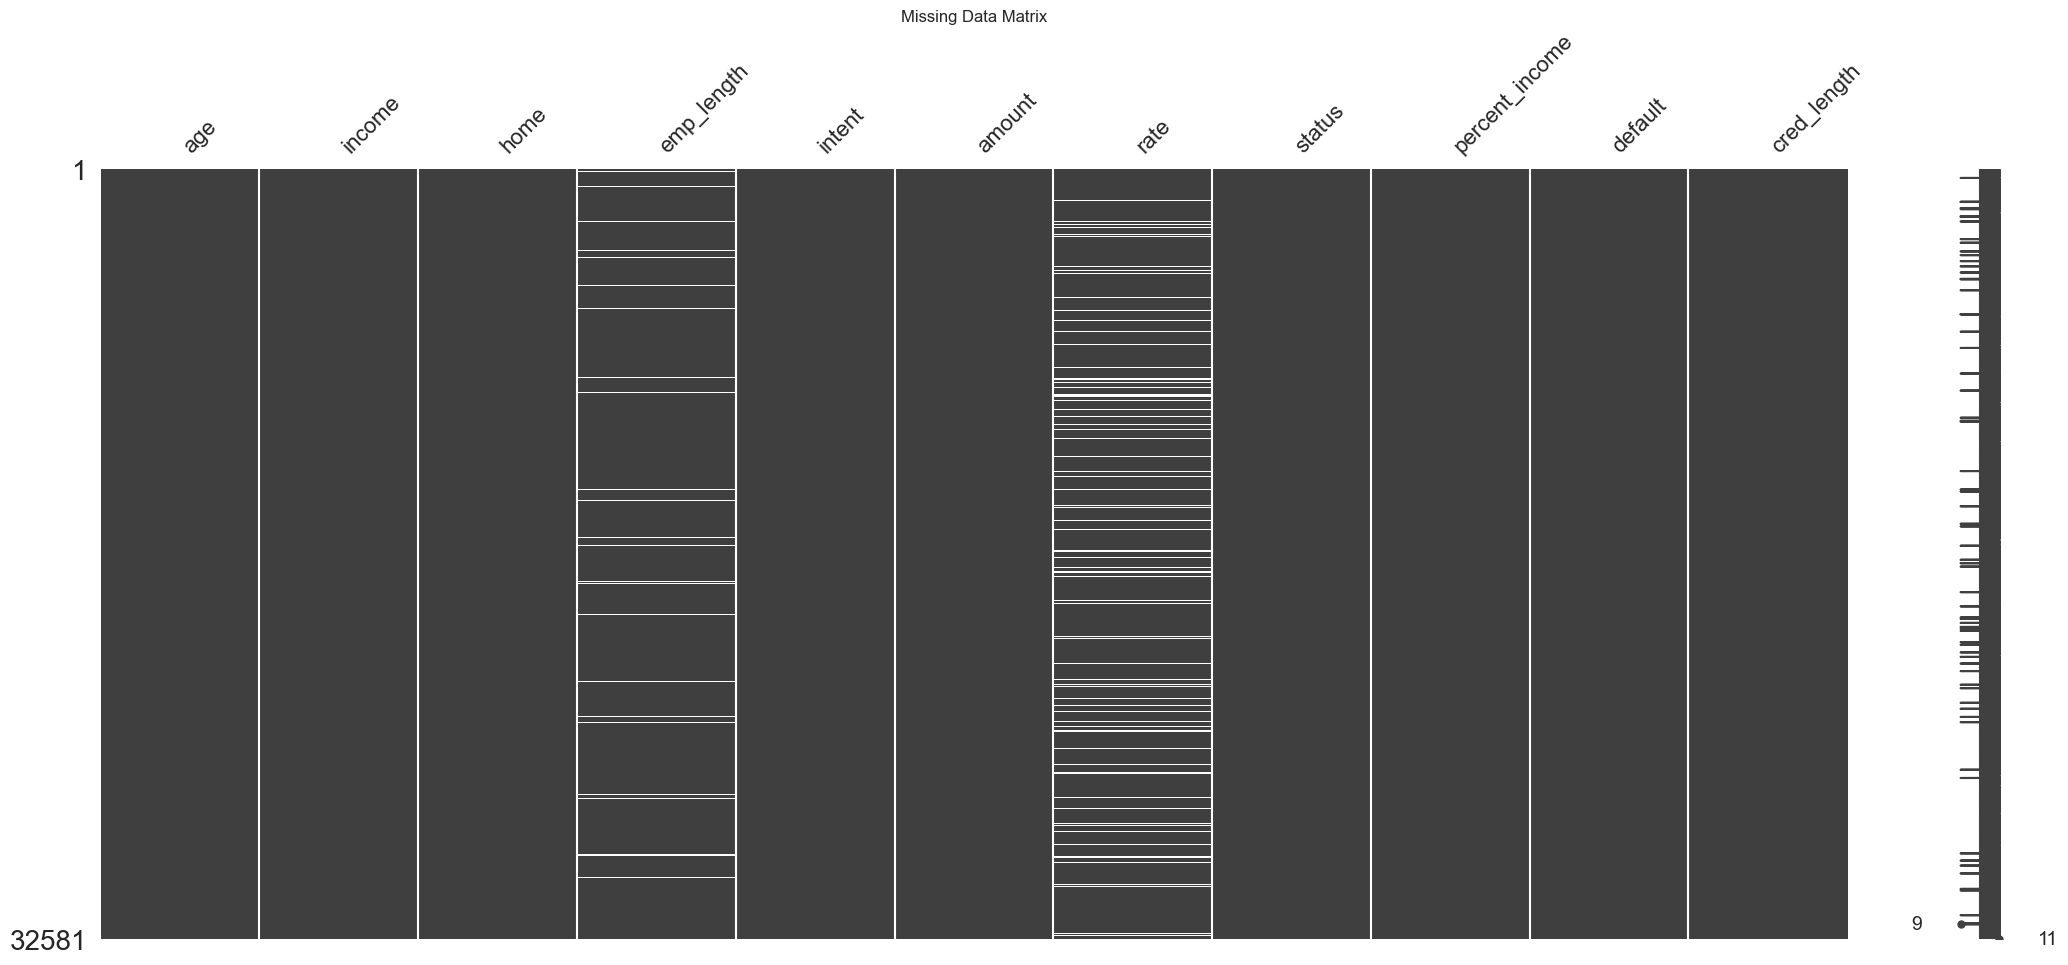

In [14]:
msno.matrix(df)
plt.title("Missing Data Matrix")
plt.show()


Based on these patterns, I can analyze the type of missingness:
Most likely: MAR (Missing At Random)
The pattern suggests this might be survey or administrative data where certain questions were conditionally asked or where data integration from multiple sources led to systematic gaps

### Drop rows with missing values in 'Emp_length' and 'Rate' columns
### Reason: These columns have a small percentage of missing data
### - Emp_length missing: ~2.75%
### - Rate missing: ~9.56%
### So it's safe to drop them without significantly affecting the dataset

In [15]:
# Drop missing values in 'Emp_length' and 'Rate
df = df.dropna(subset=['emp_length', 'rate'])
# Reset index after dropping rows
df = df.reset_index(drop=True)

### Checking if there are any duplicate values

In [16]:
#there is no duplicated
df.duplicated().sum()

137

In [17]:
num_cols = list(df.select_dtypes(include='number').columns)
cat_cols =  list(df.select_dtypes(include='object').columns)

print(num_cols)
print(cat_cols)

['age', 'income', 'emp_length', 'amount', 'rate', 'status', 'percent_income', 'cred_length']
['home', 'intent', 'default']


## checking for any outlayers


Column: age
Number of outliers: 566
Outlier values:
[144 144 123  50  46  47  46  48  50  46  46  47  46  47  48  50  48  47
  46  48  50  50  47  48  50  49  46  49  48  50  48  49  46  48  50  48
  48  48  47  48  46  48  46  48  46  49  47  47  48  47  47  47  47  47
  46  50  47  49  48  48  46  47  47  46  50  47  48  46  46  46  50  50
  47  46  46  49  48  49  49  47  49  47  50  50  50  49  50  48  50  47
  47  47  47  47  46  48  47  48  46  50  50  50  47  46  46  46  48  48
  47  48  48  47  48  48  46  49  48  47  49  50  46  48  46  48  50  46
  47  47  47  46  47  48  47  46  47  46  46  48  46  50  48  46  48  47
  46  50  46  48  48  47  46  49  49  48  48  46  49  49  50  47  49  47
  47  48  48  46  50  47  50  50  48  47  48  46  49  49  50  48  48  48
  46  46  50  50  46  46  46  49  46  46  47  46  49  48  48  47  50  47
  48  47  49  46  46  47  46  48  49  46  48  49  47  48  47  46  47  46
  48  46  49  49  46  49  49  50  46  46  50  47  46  47  49  49  46  4

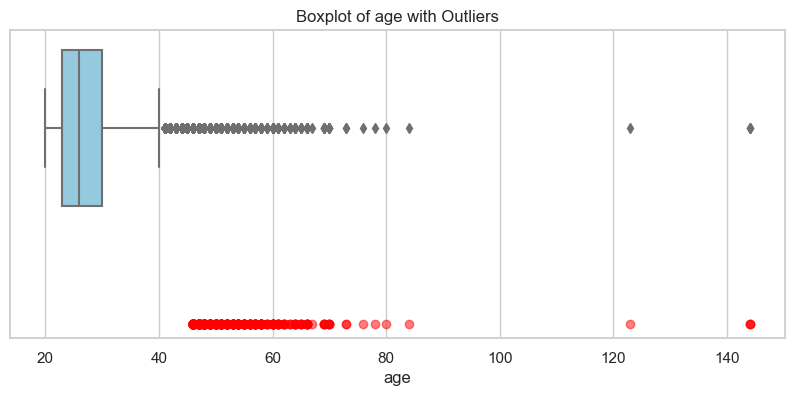


Column: income
Number of outliers: 818
Outlier values:
[ 500000  306000  300000  300000  300000  300000  300000  300000  280000
  277104  275000  221850  260000  259000  255000  250000  250000  250000
  234000  234000  234000  221004  232500  230000  226000  225000  213000
  225000  225000  225000  225000  220000  216000  216000  216000  215000
  215000  210000  210000  203500  190000  200000  200000  200000  200000
  200000  200000  200000  200000  200000  200000  200000  200000  200000
  200000  188000  200000  192000  191000  190000  189996  186000  185000
  185000  185000  184992  184000  172000  183000  182952  180000  180000
  180000  180000  180000  180000  180000  180000  180000  175000  175000
  175000  175000  175000  174708  174000  174000  173467  171500  170004
  170000  170000  170000  170000  169000  168750  168600  168288  168000
  165000  165000  165000  165000  175000  185000  225000  287000  168000
  172500  175000  175000  175000  200004  210000  165000  185000  20

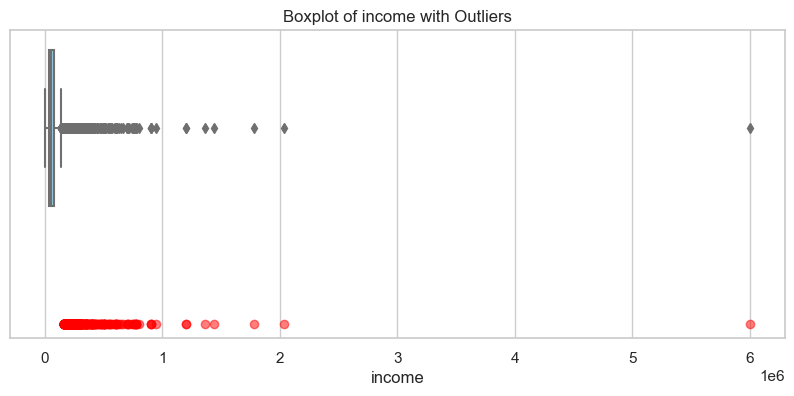


Column: emp_length
Number of outliers: 197
Outlier values:
[123. 123.  19.  19.  19.  19.  19.  19.  19.  19.  19.  19.  19.  19.
  19.  19.  19.  19.  19.  19.  19.  19.  19.  19.  19.  19.  19.  19.
  19.  19.  19.  19.  19.  19.  22.  19.  19.  19.  22.  22.  19.  20.
  20.  22.  21.  21.  20.  19.  24.  23.  21.  22.  22.  20.  21.  24.
  21.  23.  20.  21.  21.  20.  20.  21.  20.  19.  19.  26.  19.  19.
  26.  24.  19.  25.  20.  23.  19.  23.  21.  21.  20.  22.  22.  21.
  19.  27.  20.  19.  27.  25.  21.  19.  20.  25.  20.  20.  19.  24.
  19.  20.  19.  31.  25.  20.  21.  22.  25.  23.  21.  21.  19.  26.
  19.  25.  21.  21.  19.  22.  19.  19.  20.  20.  20.  20.  28.  19.
  20.  19.  21.  21.  23.  20.  19.  22.  25.  22.  21.  20.  22.  20.
  20.  23.  22.  20.  22.  27.  21.  21.  20.  19.  19.  21.  24.  22.
  21.  20.  21.  31.  31.  20.  26.  21.  20.  22.  21.  21.  21.  21.
  28.  25.  21.  20.  31.  20.  21.  22.  19.  19.  24.  21.  41.  27.
  20.  24.  20.  

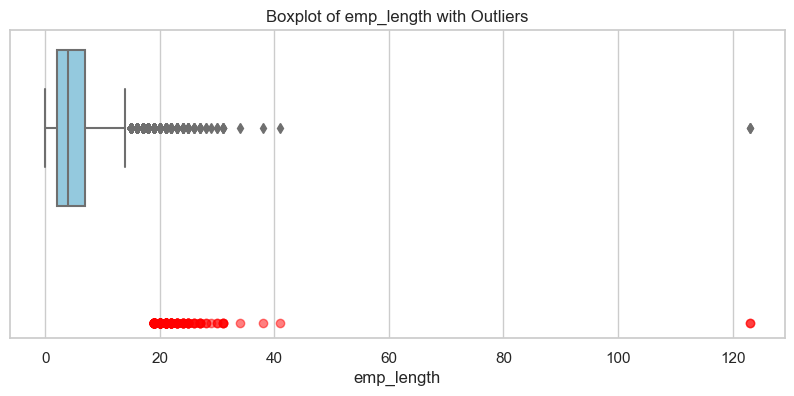


Column: amount
Number of outliers: 188
Outlier values:
[35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000
 35000 35000 34800 34000 33950 33000 32500 32000 31050 35000 35000 35000
 35000 35000 35000 31300 35000 35000 35000 31825 35000 35000 35000 35000
 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000
 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000
 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000
 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000
 35000 35000 35000 35000 35000 35000 35000 35000 35000 34000 32000 35000
 32000 32000 31000 35000 35000 35000 35000 35000 35000 35000 35000 31000
 35000 35000 32000 35000 32000 31825 35000 35000 35000 35000 33950 35000
 35000 35000 35000 35000 35000 33000 35000 35000 35000 35000 35000 32000
 35000 33250 32000 35000 35000 35000 35000 35000 35000 35000 35000 34000
 35000 33000 35000 35000 35000 35000 35000 35000 32000 35000 35000 3

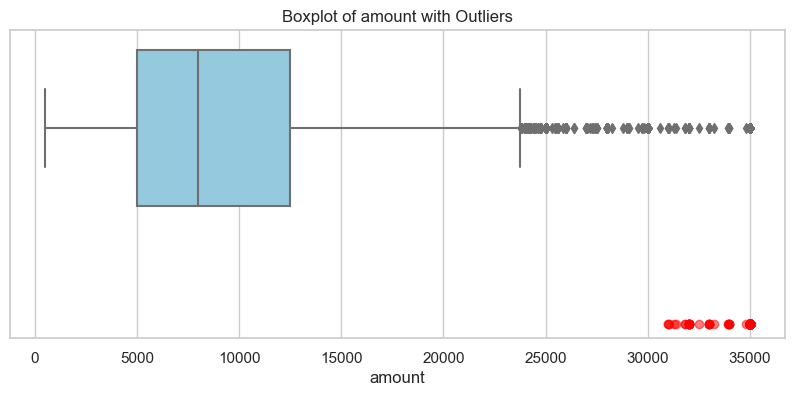


Column: rate
Number of outliers: 0


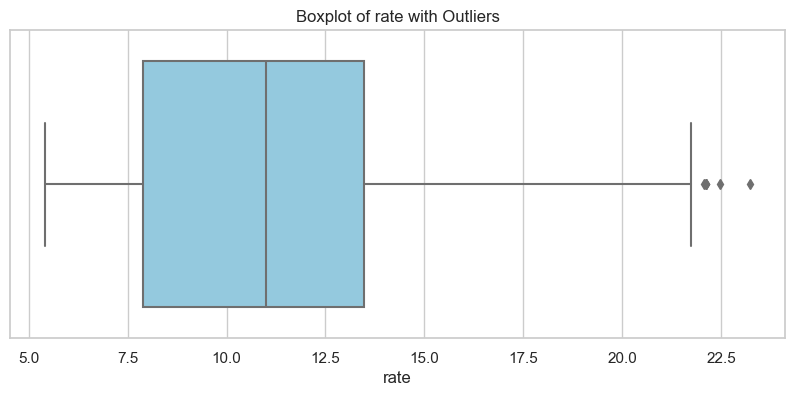


Column: status
Number of outliers: 0


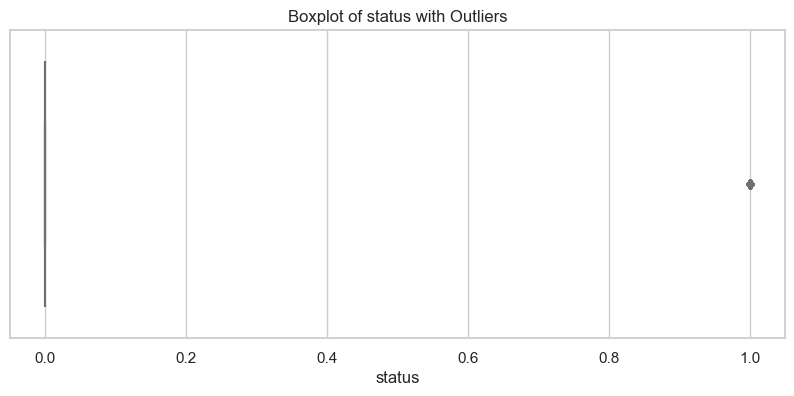


Column: percent_income
Number of outliers: 218
Outlier values:
[0.59 0.57 0.53 0.55 0.52 0.63 0.51 0.59 0.6  0.52 0.59 0.51 0.51 0.57
 0.54 0.53 0.53 0.52 0.56 0.56 0.51 0.53 0.51 0.72 0.56 0.64 0.51 0.69
 0.6  0.53 0.77 0.77 0.61 0.57 0.53 0.63 0.53 0.52 0.61 0.59 0.54 0.53
 0.51 0.83 0.65 0.51 0.54 0.51 0.54 0.52 0.53 0.51 0.51 0.67 0.55 0.59
 0.54 0.58 0.53 0.56 0.65 0.69 0.51 0.57 0.51 0.55 0.54 0.54 0.71 0.56
 0.64 0.52 0.51 0.52 0.68 0.59 0.53 0.53 0.55 0.64 0.54 0.51 0.51 0.7
 0.63 0.51 0.56 0.53 0.59 0.59 0.54 0.56 0.52 0.71 0.56 0.52 0.6  0.51
 0.53 0.55 0.52 0.63 0.54 0.52 0.52 0.7  0.52 0.52 0.54 0.54 0.64 0.66
 0.52 0.68 0.65 0.55 0.51 0.53 0.52 0.57 0.52 0.51 0.51 0.52 0.66 0.6
 0.59 0.56 0.68 0.63 0.53 0.52 0.52 0.52 0.51 0.64 0.76 0.67 0.51 0.59
 0.53 0.63 0.67 0.51 0.54 0.52 0.58 0.6  0.55 0.7  0.51 0.53 0.53 0.53
 0.53 0.58 0.55 0.6  0.53 0.52 0.59 0.53 0.63 0.54 0.55 0.56 0.55 0.54
 0.51 0.52 0.53 0.62 0.59 0.59 0.58 0.78 0.52 0.52 0.53 0.58 0.63 0.61
 0.6  0.52 0.52

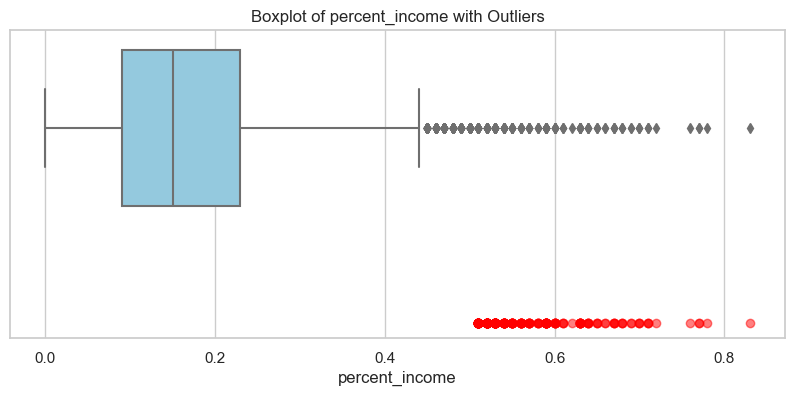


Column: cred_length
Number of outliers: 235
Outlier values:
[25 28 27 22 19 19 19 29 23 26 23 27 23 28 22 20 21 23 20 20 30 25 21 22
 23 29 30 21 25 19 24 19 29 21 27 28 28 24 22 21 24 25 21 21 27 27 27 20
 30 20 25 25 30 21 19 22 25 27 24 30 27 22 19 23 24 29 25 28 27 24 22 20
 20 28 28 27 24 22 24 20 25 25 25 28 22 30 22 22 20 24 20 20 30 23 23 19
 28 19 26 28 26 21 23 29 30 25 24 26 29 29 21 24 22 24 26 25 19 24 27 26
 26 23 27 22 20 19 30 28 24 24 20 24 26 19 27 29 30 22 23 30 20 25 22 24
 28 20 20 19 20 20 29 28 21 24 30 20 21 28 22 28 23 23 27 30 23 30 27 21
 28 22 24 27 26 24 26 30 20 20 19 25 23 23 20 22 20 29 23 21 24 22 22 20
 25 27 21 26 24 25 28 26 20 20 30 26 30 20 28 28 23 24 19 29 20 28 23 24
 24 27 24 21 24 28 21 26 21 26 22 19 19 20 30 19 28 26 30]


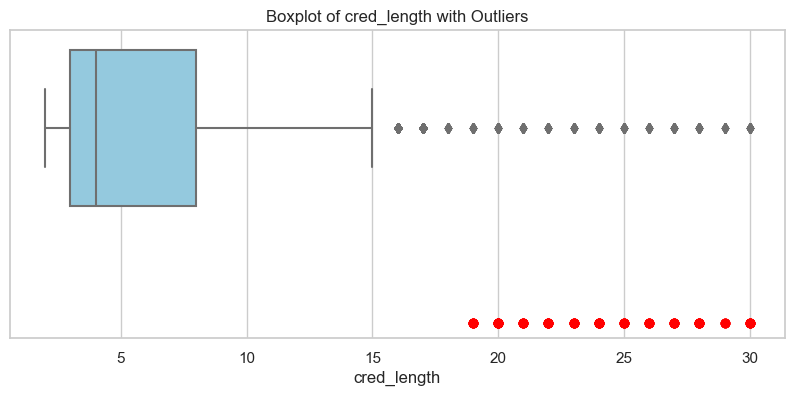


Total number of outliers in all numeric columns: 2222


In [18]:
# Initialize total outlier counter
total_outliers = 0

# Loop through all numeric columns
for col in num_cols:
    # Calculate IQR
    Q1 = df[col].quantile(0.20)
    Q3 = df[col].quantile(0.80)
    IQR = Q3 - Q1

    # Calculate bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = df[col][(df[col] < lower_bound) | (df[col] > upper_bound)]

    # Update total outlier count
    total_outliers += len(outliers)

    # Print results
    print(f"\nColumn: {col}")
    print(f"Number of outliers: {len(outliers)}")
    if len(outliers) > 0:
        print("Outlier values:")
        print(outliers.values)

    # Plot boxplot with outliers highlighted
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot of {col} with Outliers')
    plt.xlabel(col)

    # Mark outliers in red
    for outlier in outliers:
        plt.plot(outlier, 1, 'ro', alpha=0.5)

    plt.show()

# Print total number of outliers across all numeric columns
print(f"\nTotal number of outliers in all numeric columns: {total_outliers}")


### I have strange values like 144, 123 — clearly data entry errors.

In [19]:
df = df[(df['age'] <= 100)]

### Realistic employment length usually is 0 to 40 years

In [20]:
df = df[df['emp_length'] <= 40]


### Outliers like 6,000,000 or 1,782,000 — extreme and unrealistic for general applicants
### Cap values at a threshold using winsorization

In [21]:
df['income'] = df['income'].clip(upper=df['income'].quantile(0.99))

In [22]:
num_cols = list(df.select_dtypes(include='number').columns)
cat_cols =  list(df.select_dtypes(include='object').columns)

print(num_cols)
print(cat_cols)

['age', 'income', 'emp_length', 'amount', 'rate', 'status', 'percent_income', 'cred_length']
['home', 'intent', 'default']



Column: age
Number of outliers: 561
Outlier values:
[50 46 47 46 48 50 46 46 47 46 47 48 50 48 47 46 48 50 50 47 48 50 49 46
 49 48 50 48 49 46 48 50 48 48 48 47 48 46 48 46 48 46 49 47 47 48 47 47
 47 47 47 46 50 47 49 48 48 46 47 47 46 50 47 48 46 46 46 50 50 47 46 46
 49 48 49 49 47 49 47 50 50 50 49 50 48 50 47 47 47 47 47 46 48 47 48 46
 50 50 50 47 46 46 46 48 48 47 48 48 47 48 48 46 49 48 47 49 50 46 48 46
 48 50 46 47 47 47 46 47 48 47 46 47 46 46 48 46 50 48 46 48 47 46 50 46
 48 48 47 46 49 49 48 48 46 49 49 50 47 49 47 47 48 48 46 50 47 50 50 48
 47 48 46 49 49 50 48 48 48 46 46 50 50 46 46 46 49 46 46 47 46 49 48 48
 47 50 47 48 47 49 46 46 47 46 48 49 46 48 49 47 48 47 46 47 46 48 46 49
 49 46 49 49 50 46 46 50 47 46 47 49 49 46 48 46 47 48 50 47 49 46 50 49
 49 46 46 50 48 46 47 49 48 46 49 46 46 46 50 47 50 49 47 46 50 46 46 50
 48 47 49 47 47 46 47 46 48 47 47 47 46 47 47 46 47 50 46 50 50 48 47 47
 46 47 48 46 48 49 47 47 48 50 46 47 46 46 49 46 48 46 49 49 47 47 46 4

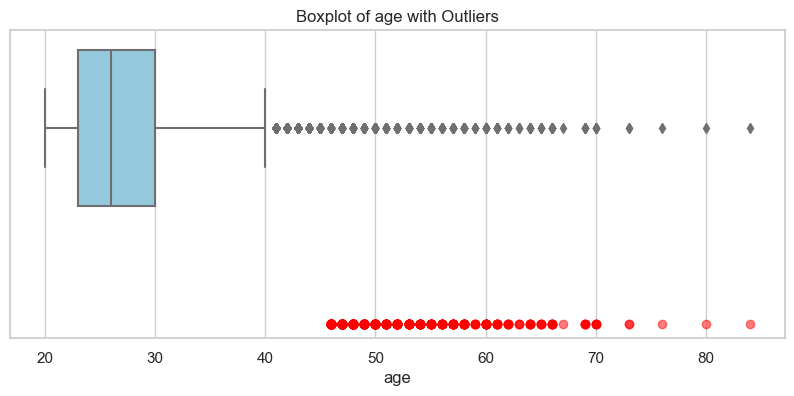


Column: income
Number of outliers: 814
Outlier values:
[230000 230000 230000 230000 230000 230000 230000 230000 230000 230000
 230000 221850 230000 230000 230000 230000 230000 230000 230000 230000
 221004 230000 230000 226000 225000 213000 225000 225000 225000 225000
 220000 216000 216000 216000 215000 215000 210000 210000 203500 190000
 200000 200000 200000 200000 200000 200000 200000 200000 200000 200000
 200000 200000 200000 188000 200000 191000 190000 189996 186000 185000
 185000 185000 184992 184000 172000 183000 182952 180000 180000 180000
 180000 180000 180000 180000 180000 180000 175000 175000 175000 175000
 175000 174708 174000 174000 173467 171500 170004 170000 170000 170000
 170000 169000 168750 168600 168288 168000 165000 165000 165000 165000
 175000 185000 225000 230000 168000 172500 175000 175000 175000 200004
 210000 165000 185000 200004 180000 165000 165000 175000 230000 230000
 183700 180000 170000 225000 190000 165000 165000 165500 166000 167300
 168000 170000 170000

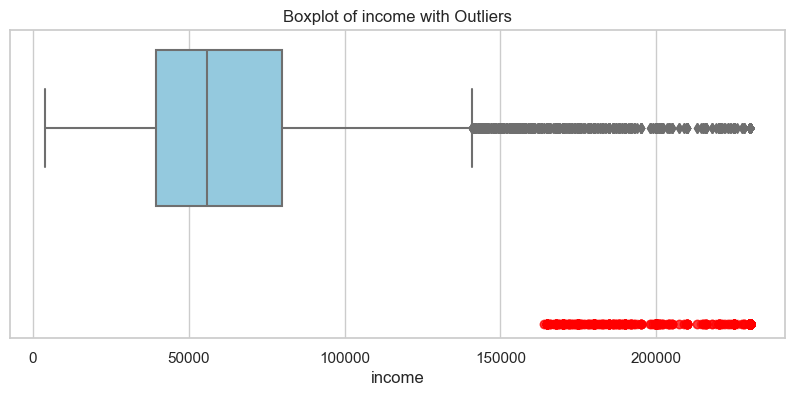


Column: emp_length
Number of outliers: 194
Outlier values:
[19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19.
 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 19. 22. 19. 19. 19.
 22. 22. 19. 20. 20. 22. 21. 21. 20. 19. 24. 23. 21. 22. 22. 20. 21. 24.
 21. 23. 20. 21. 21. 20. 20. 21. 20. 19. 19. 26. 19. 19. 26. 24. 19. 25.
 20. 23. 19. 23. 21. 21. 20. 22. 22. 21. 19. 27. 20. 19. 27. 25. 21. 19.
 20. 25. 20. 20. 19. 24. 19. 20. 19. 31. 25. 20. 21. 22. 25. 23. 21. 21.
 19. 26. 19. 25. 21. 21. 19. 22. 19. 19. 20. 20. 20. 20. 28. 19. 20. 19.
 21. 21. 23. 20. 19. 22. 25. 22. 21. 20. 22. 20. 20. 23. 22. 20. 22. 27.
 21. 21. 20. 19. 19. 21. 24. 22. 21. 20. 21. 31. 31. 20. 26. 21. 20. 22.
 21. 21. 21. 21. 28. 25. 21. 20. 31. 20. 21. 22. 19. 19. 24. 21. 27. 20.
 24. 20. 20. 34. 23. 20. 29. 27. 24. 38. 23. 23. 30. 30.]


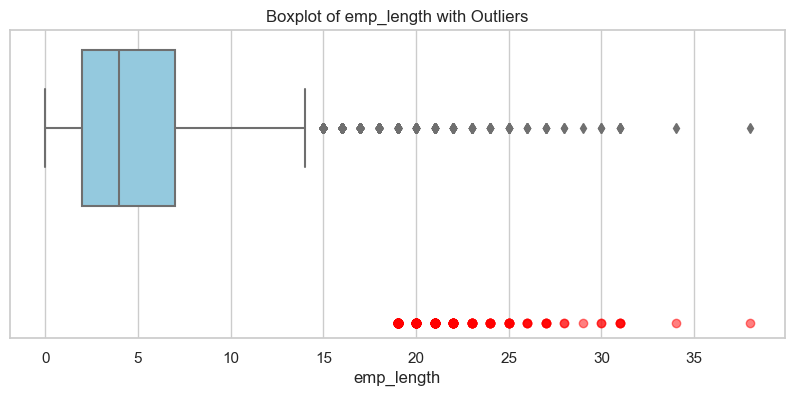


Column: amount
Number of outliers: 187
Outlier values:
[35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000
 35000 34800 34000 33950 33000 32500 32000 31050 35000 35000 35000 35000
 35000 35000 31300 35000 35000 35000 31825 35000 35000 35000 35000 35000
 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000
 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000
 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000
 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000 35000
 35000 35000 35000 35000 35000 35000 35000 35000 34000 32000 35000 32000
 32000 31000 35000 35000 35000 35000 35000 35000 35000 35000 31000 35000
 35000 32000 35000 32000 31825 35000 35000 35000 35000 33950 35000 35000
 35000 35000 35000 35000 33000 35000 35000 35000 35000 35000 32000 35000
 33250 32000 35000 35000 35000 35000 35000 35000 35000 35000 34000 35000
 33000 35000 35000 35000 35000 35000 35000 32000 35000 35000 35000 3

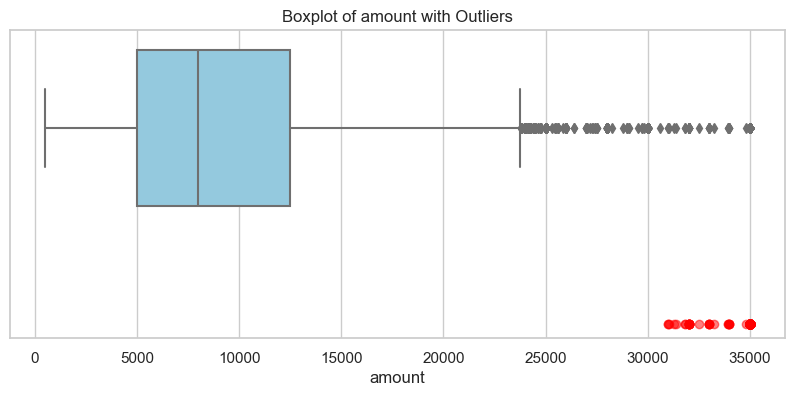


Column: rate
Number of outliers: 0


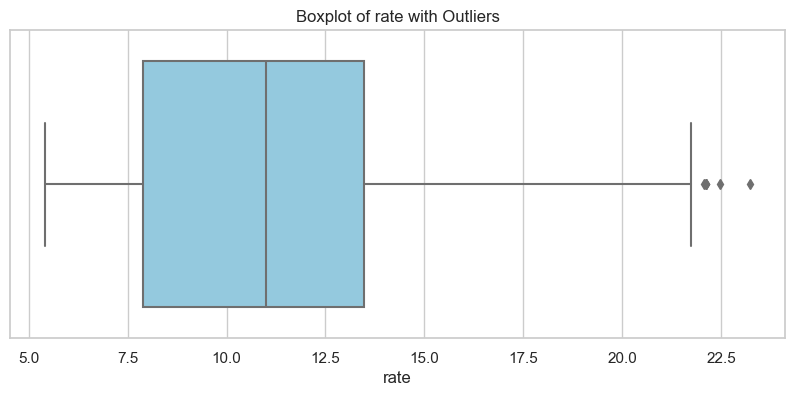


Column: status
Number of outliers: 0


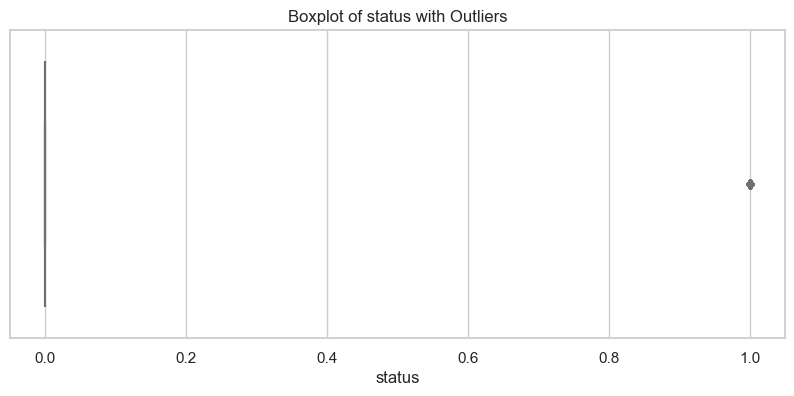


Column: percent_income
Number of outliers: 217
Outlier values:
[0.57 0.53 0.55 0.52 0.63 0.51 0.59 0.6  0.52 0.59 0.51 0.51 0.57 0.54
 0.53 0.53 0.52 0.56 0.56 0.51 0.53 0.51 0.72 0.56 0.64 0.51 0.69 0.6
 0.53 0.77 0.77 0.61 0.57 0.53 0.63 0.53 0.52 0.61 0.59 0.54 0.53 0.51
 0.83 0.65 0.51 0.54 0.51 0.54 0.52 0.53 0.51 0.51 0.67 0.55 0.59 0.54
 0.58 0.53 0.56 0.65 0.69 0.51 0.57 0.51 0.55 0.54 0.54 0.71 0.56 0.64
 0.52 0.51 0.52 0.68 0.59 0.53 0.53 0.55 0.64 0.54 0.51 0.51 0.7  0.63
 0.51 0.56 0.53 0.59 0.59 0.54 0.56 0.52 0.71 0.56 0.52 0.6  0.51 0.53
 0.55 0.52 0.63 0.54 0.52 0.52 0.7  0.52 0.52 0.54 0.54 0.64 0.66 0.52
 0.68 0.65 0.55 0.51 0.53 0.52 0.57 0.52 0.51 0.51 0.52 0.66 0.6  0.59
 0.56 0.68 0.63 0.53 0.52 0.52 0.52 0.51 0.64 0.76 0.67 0.51 0.59 0.53
 0.63 0.67 0.51 0.54 0.52 0.58 0.6  0.55 0.7  0.51 0.53 0.53 0.53 0.53
 0.58 0.55 0.6  0.53 0.52 0.59 0.53 0.63 0.54 0.55 0.56 0.55 0.54 0.51
 0.52 0.53 0.62 0.59 0.59 0.58 0.78 0.52 0.52 0.53 0.58 0.63 0.61 0.6
 0.52 0.52 0.51

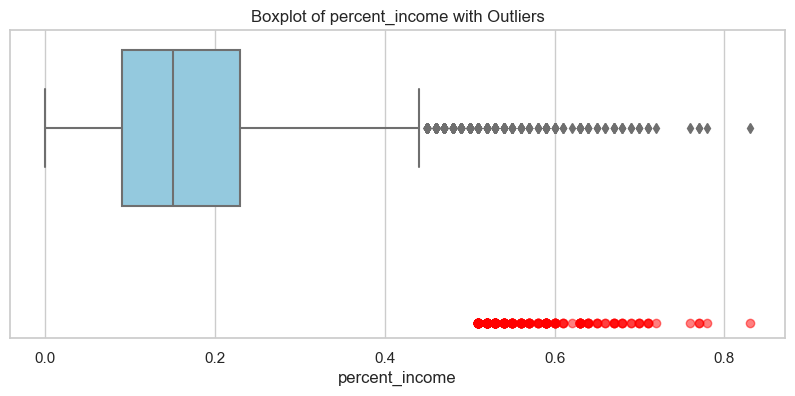


Column: cred_length
Number of outliers: 233
Outlier values:
[28 27 22 19 19 19 29 23 26 23 27 23 28 22 20 21 23 20 20 30 25 21 22 23
 29 30 21 25 19 24 19 29 21 27 28 28 24 22 21 24 25 21 21 27 27 27 20 30
 20 25 30 21 19 22 25 27 24 30 27 22 19 23 24 29 25 28 27 24 22 20 20 28
 28 27 24 22 24 20 25 25 25 28 22 30 22 22 20 24 20 20 30 23 23 19 28 19
 26 28 26 21 23 29 30 25 24 26 29 29 21 24 22 24 26 25 19 24 27 26 26 23
 27 22 20 19 30 28 24 24 20 24 26 19 27 29 30 22 23 30 20 25 22 24 28 20
 20 19 20 20 29 28 21 24 30 20 21 28 22 28 23 23 27 30 23 30 27 21 28 22
 24 27 26 24 26 30 20 20 19 25 23 23 20 22 20 29 23 21 24 22 22 20 25 27
 21 26 24 25 28 26 20 20 30 26 30 20 28 28 23 24 19 29 20 28 23 24 24 27
 24 21 24 28 21 26 21 26 22 19 19 20 30 19 28 26 30]


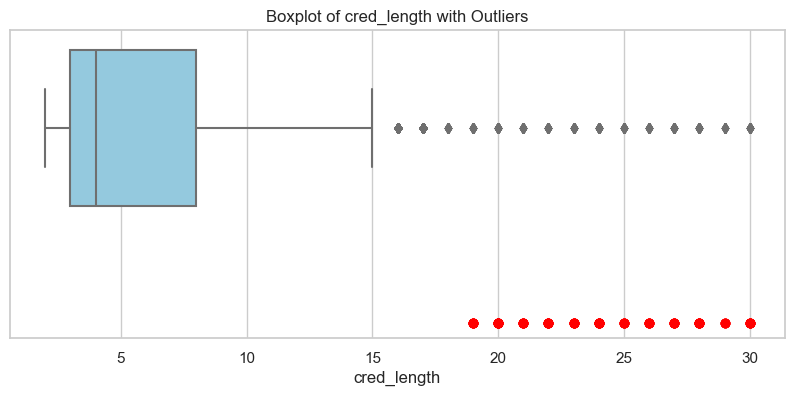


Total number of outliers in all numeric columns: 2206


In [23]:
# Initialize total outlier counter
total_outliers = 0

# Loop through all numeric columns
for col in num_cols:
    # Calculate IQR
    Q1 = df[col].quantile(0.20)
    Q3 = df[col].quantile(0.80)
    IQR = Q3 - Q1

    # Calculate bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = df[col][(df[col] < lower_bound) | (df[col] > upper_bound)]

    # Update total outlier count
    total_outliers += len(outliers)

    # Print results
    print(f"\nColumn: {col}")
    print(f"Number of outliers: {len(outliers)}")
    if len(outliers) > 0:
        print("Outlier values:")
        print(outliers.values)

    # Plot boxplot with outliers highlighted
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot of {col} with Outliers')
    plt.xlabel(col)

    # Mark outliers in red
    for outlier in outliers:
        plt.plot(outlier, 1, 'ro', alpha=0.5)

    plt.show()

# Print total number of outliers across all numeric columns
print(f"\nTotal number of outliers in all numeric columns: {total_outliers}")


## Numerical Features Distribution

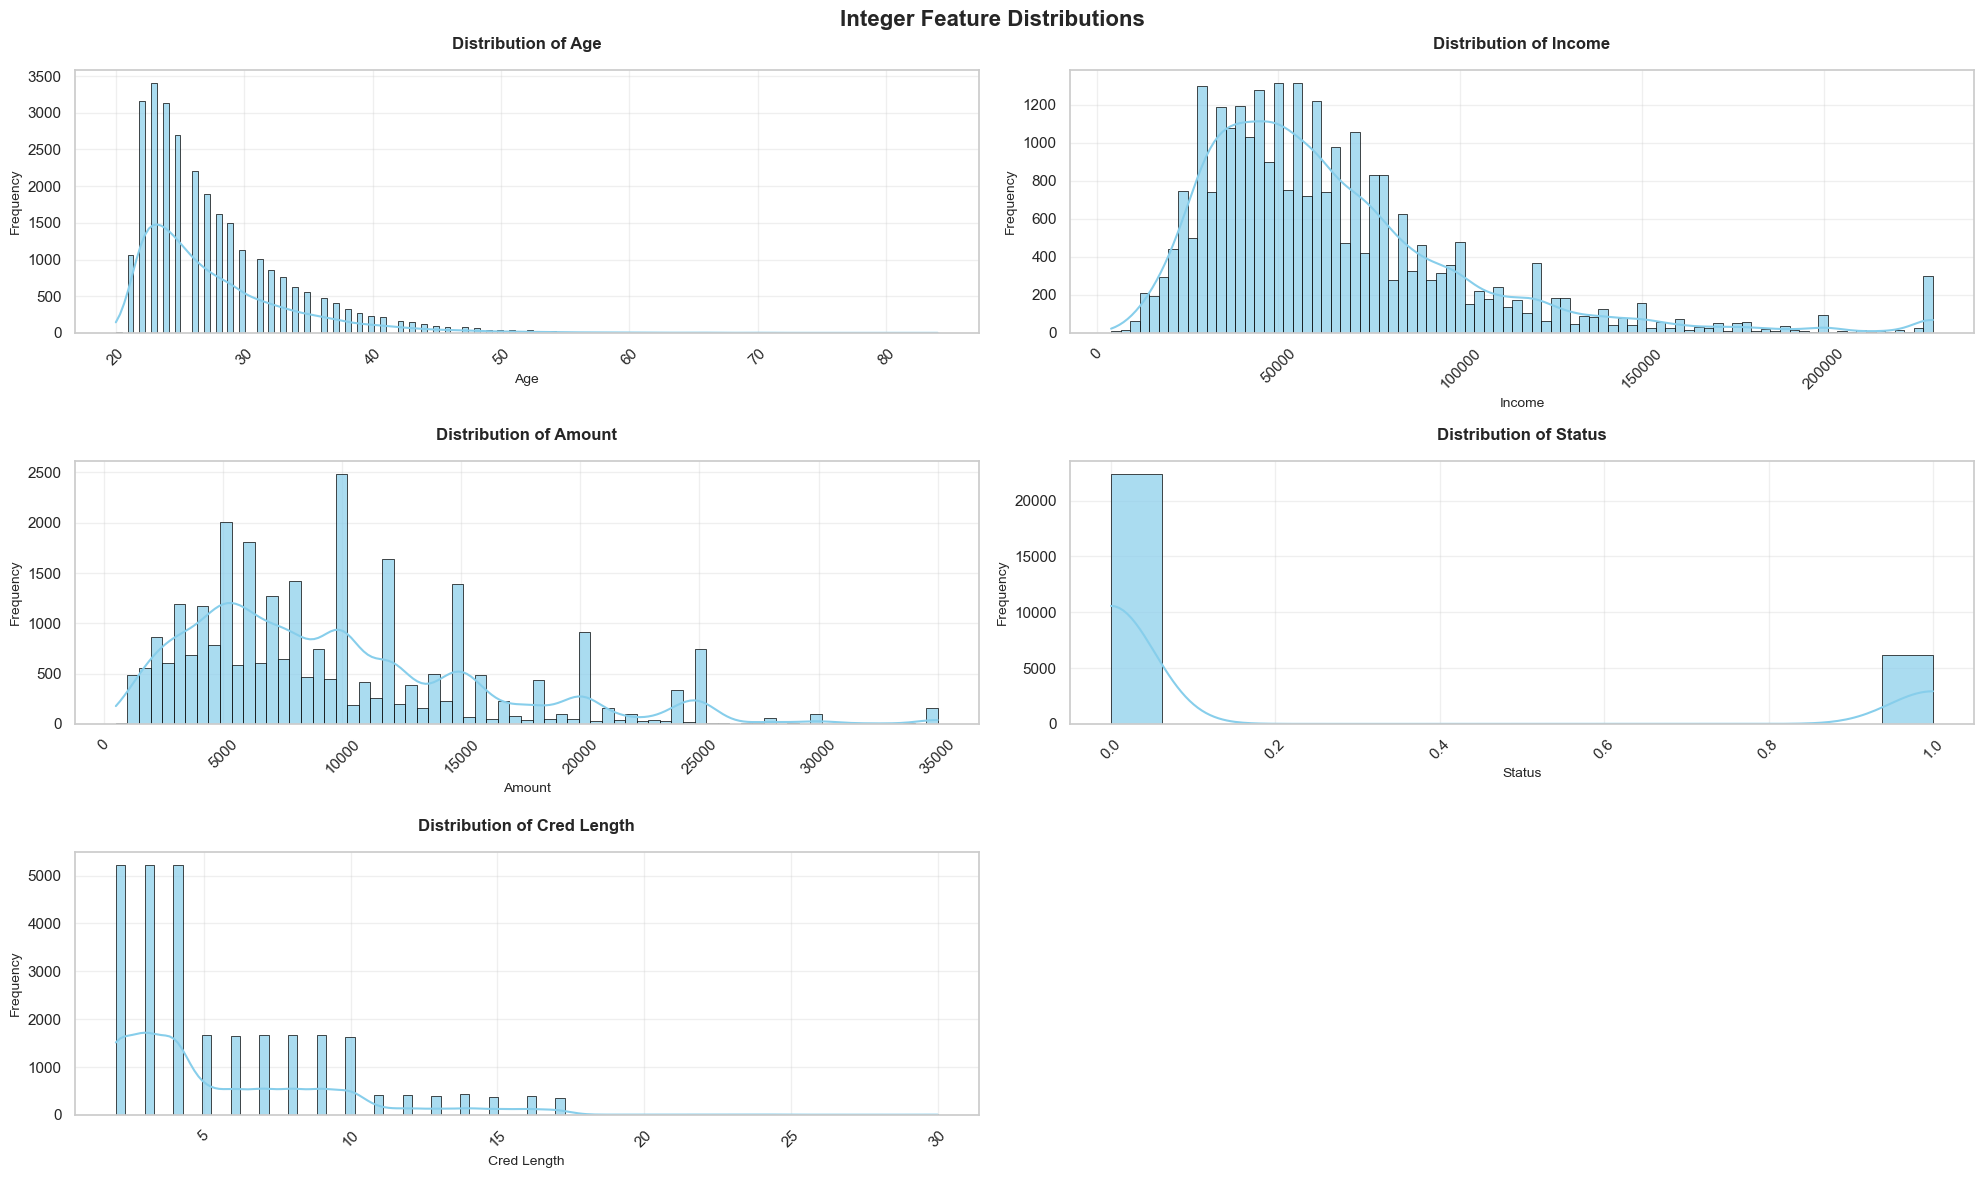

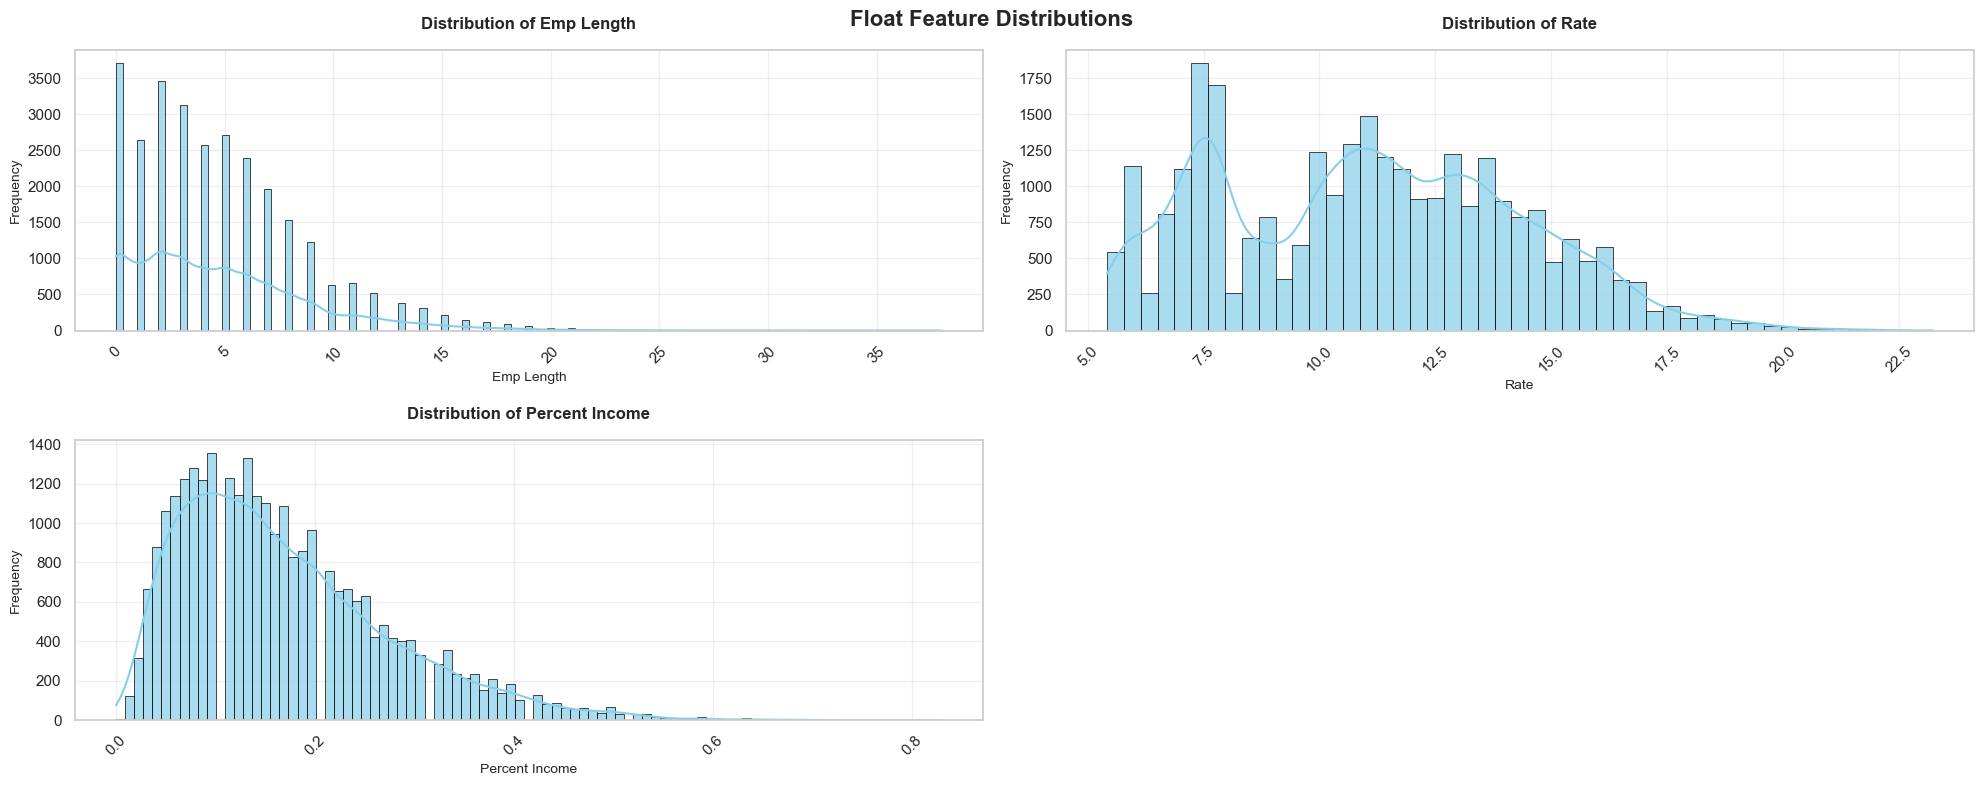

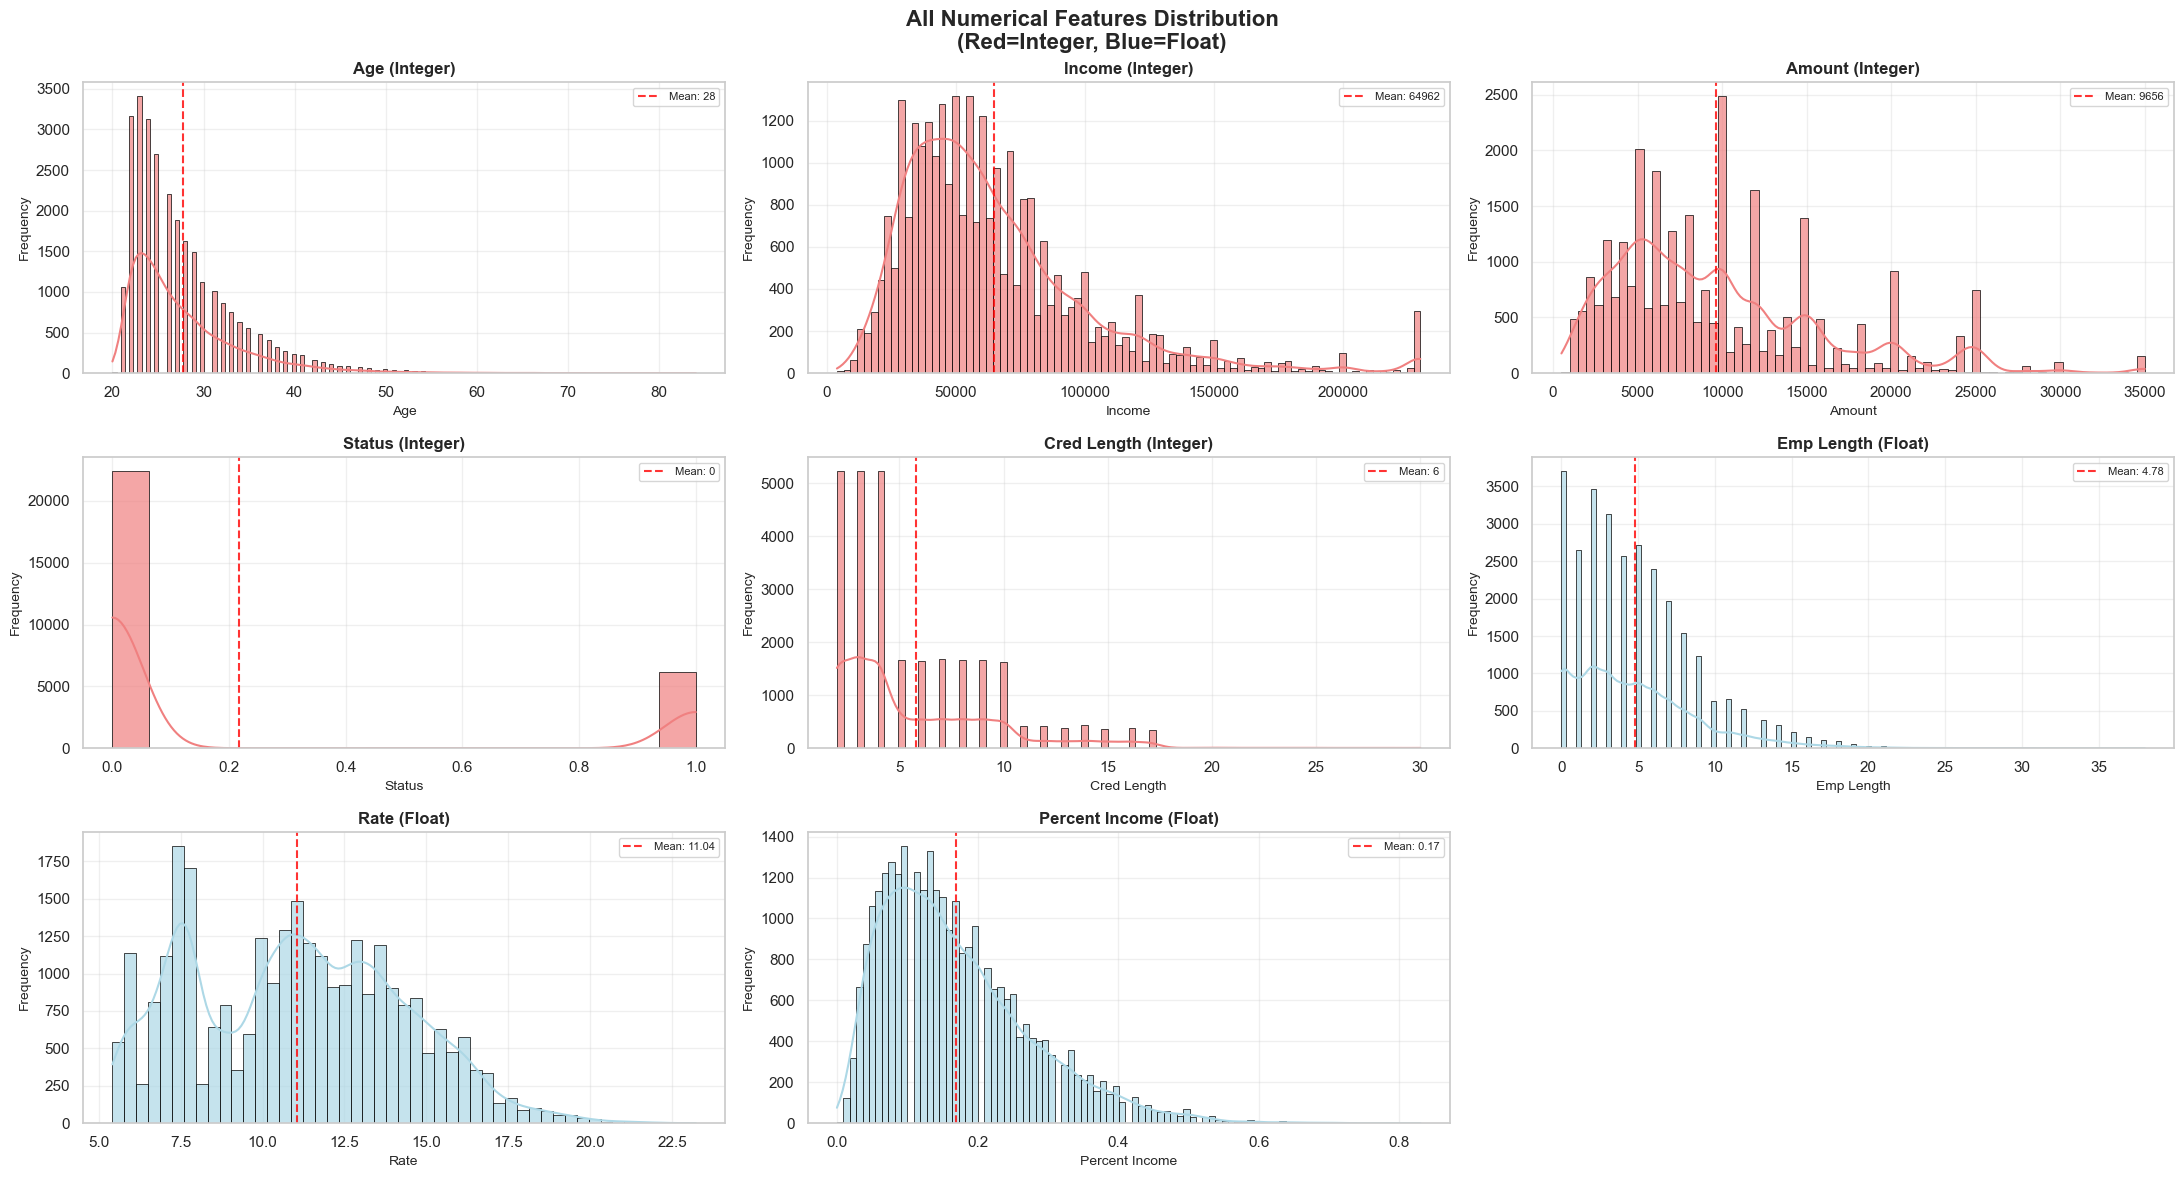

In [24]:
# Separate integer and float columns
int_cols = df.select_dtypes(include=['int64']).columns.tolist()
float_cols = df.select_dtypes(include=['float64']).columns.tolist()

# Remove 'id' from int_cols 
if 'id' in int_cols:
    int_cols.remove('id')


# Function to create better distribution plots
def plot_distributions(columns, title, figsize=(20, 12)):

    ncols = 2 
    nrows = int(np.ceil(len(columns) / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    
 
    # Flatten axes for easier indexing
    axes_flat = axes.flatten() if nrows > 1 or len(columns) > 1 else [axes]
    
    for i, col in enumerate(columns):
        ax = axes_flat[i]
        
        # Create histogram with better styling
        sns.histplot(data=df, x=col, kde=True, ax=ax, 
                    color='skyblue', alpha=0.7, edgecolor='black', linewidth=0.5)
        



        # Improve titles and labels
        ax.set_title(f'Distribution of {col.replace("_", " ").title()}', 
                    fontsize=12, fontweight='bold', pad=15)
        ax.set_xlabel(col.replace("_", " ").title(), fontsize=10)
        ax.set_ylabel('Frequency', fontsize=10)
        
        # Add grid for better readability
        ax.grid(True, alpha=0.3)
        
        # Rotate x-axis labels if they're too long
        ax.tick_params(axis='x', rotation=45)
    
    # Hide empty subplots
    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].set_visible(False)
    
    plt.suptitle(title, fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.subplots_adjust(top=0.93)  # Make room for suptitle
    plt.show()

# Plot integer columns
plot_distributions(int_cols, "Integer Feature Distributions", figsize=(20, 12))

# Plot float columns
plot_distributions(float_cols, "Float Feature Distributions", figsize=(20, 8))

# Combined view with different colors
def plot_combined_distributions():
    all_num_cols = int_cols + float_cols
    if not all_num_cols:
        return
    
    ncols = 3
    nrows = int(np.ceil(len(all_num_cols) / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(22, 4*nrows))
    
    # Handle single row case
    if nrows == 1:
        axes = axes.reshape(1, -1) if len(all_num_cols) > 1 else [axes]
    
    axes_flat = axes.flatten() if nrows > 1 or len(all_num_cols) > 1 else [axes]
    
    for i, col in enumerate(all_num_cols):
        ax = axes_flat[i]
        
        # Use different colors for int vs float
        color = 'lightcoral' if col in int_cols else 'lightblue'
        
        sns.histplot(data=df, x=col, kde=True, ax=ax, 
                    color=color, alpha=0.7, edgecolor='black', linewidth=0.5)
        
        # Add type indicator in title
        col_type = '(Integer)' if col in int_cols else '(Float)'
        ax.set_title(f'{col.replace("_", " ").title()} {col_type}', 
                    fontsize=12, fontweight='bold')
        ax.set_xlabel(col.replace("_", " ").title(), fontsize=10)
        ax.set_ylabel('Frequency', fontsize=10)
        ax.grid(True, alpha=0.3)
        
        # Add basic statistics
        mean_val = df[col].mean()
        if col in int_cols:
            ax.axvline(mean_val, color='red', linestyle='--', alpha=0.8, 
                      label=f'Mean: {mean_val:.0f}')
        else:
            ax.axvline(mean_val, color='red', linestyle='--', alpha=0.8, 
                      label=f'Mean: {mean_val:.2f}')
        
        ax.legend(fontsize=8)
    
    # Hide empty subplots
    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].set_visible(False)
    
    plt.suptitle("All Numerical Features Distribution\n(Red=Integer, Blue=Float)", 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    plt.show()

# Show combined view
plot_combined_distributions()

## Distribution Insights

**Skewed Variables**: Age, Income, and Amount show strong right-skewed distributions, indicating most values are concentrated at lower ranges with few extreme high values.

**Bimodal Patterns**: Status appears bimodal (concentrated at 0 and 1), while Credit Length shows discrete integer clustering with decreasing frequency.

**Normal-like Distributions**: Employment Length, Rate, and Percent Income approximate normal distributions, though Employment Length shows some right skew.

### Numeric Correlation

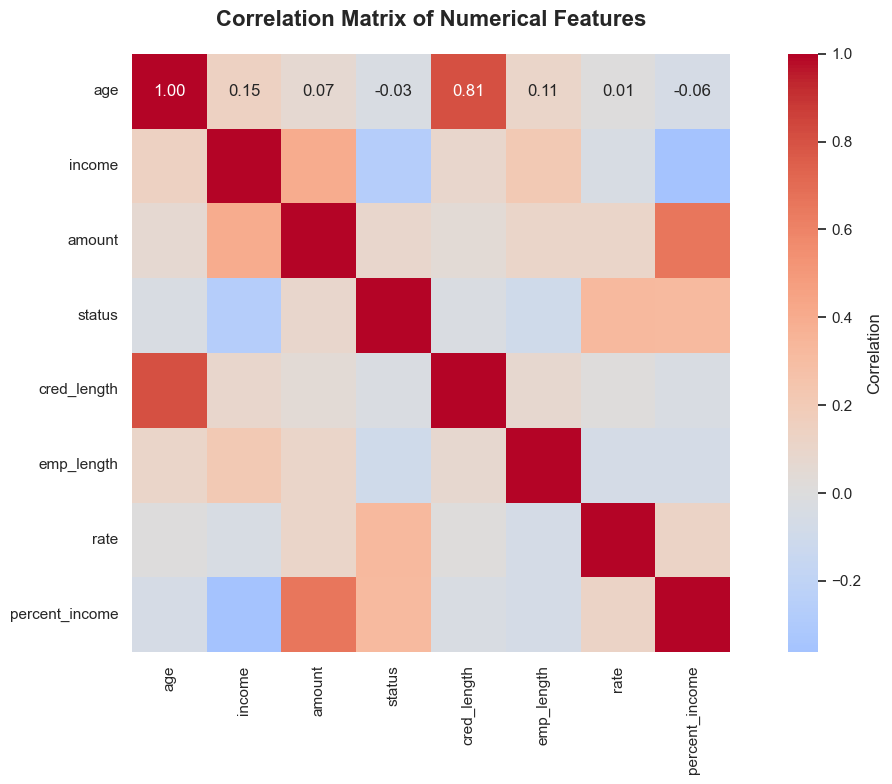

In [25]:

# Correlation heatmap for numerical features
def plot_correlation_heatmap():
    num_cols_all = int_cols + float_cols
    if len(num_cols_all) > 1:
        plt.figure(figsize=(12, 8))
        correlation_matrix = df[num_cols_all].corr(method='spearman')
        
        sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
                   square=True, fmt='.2f', cbar_kws={'label': 'Correlation'})
        plt.title('Correlation Matrix of Numerical Features', 
                 fontsize=16, fontweight='bold', pad=20)
        plt.tight_layout()
        plt.show()

# Show correlation heatmap
plot_correlation_heatmap()

## Correlation Analysis Summary

**Strong Positive Correlation**: Age and Credit Length show the highest correlation (0.81), suggesting older applicants tend to have longer credit histories.

**Weak Overall Correlations**: Most variable pairs show weak correlations (|r| < 0.3), indicating relatively independent relationships between features.

**Notable Patterns**: 
- Income and Amount have moderate positive correlation (~0.4), as expected for loan applications
- Status shows weak negative correlations with most financial variables
- Rate appears to have minimal correlation with other features

**Multicollinearity Assessment**: No severe multicollinearity issues detected, making this dataset suitable for most machine learning algorithms without extensive feature reduction.

### Categorical Distribution

In [26]:
# categorical distribution plot
def plot_categorical_distributions(df, cat_cols):
    n_unique = 5
    rotate = 45
    ncols = 2
    nrows = int(np.ceil(len(cat_cols) / ncols))
    
    plt.figure(figsize=(ncols * 6, nrows * 4))
    
    # Better color palette
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FECA57', '#FF9FF3']
    
    for i, col in enumerate(cat_cols):
        plt.subplot(nrows, ncols, i + 1)
        
        # Get value counts for better color assignment
        value_counts = df[col].value_counts()
        
        # Create countplot with improved colors
        ax = sns.countplot(data=df, x=col, palette=colors[:len(value_counts)], 
                          edgecolor='black', linewidth=0.8)
        
        # Add percentage labels on bars
        total = len(df)
        for p in ax.patches:
            percentage = f'{100 * p.get_height() / total:.1f}%'
            ax.annotate(percentage, (p.get_x() + p.get_width()/2., p.get_height()), 
                       ha='center', va='bottom', fontweight='bold')
        
        plt.title(f"Distribution of {col.title()}", fontsize=14, fontweight='bold')
        
        # Rotate x labels if too many categories
        if df[col].nunique() > n_unique:
            plt.xticks(rotation=rotate)
        
        plt.xlabel(col.title(), fontsize=12)
        plt.ylabel("Count", fontsize=12)
        plt.grid(True, alpha=0.3, axis='y')
    
    plt.suptitle("Categorical Feature Distribution", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

## Categorical Feature Distribution Summary

**Housing Status**: Most applicants are **renters (50.8%) or have mortgages (41.2%)**, with few homeowners (7.7%), suggesting a younger or urban demographic.

**Loan Purpose**: Relatively **balanced distribution** across intents, with **Education (19.9%) and Medical (18.5%) leading**, followed by Venture and Personal purposes (~17% each).

**Target Variable**: **Imbalanced dataset** with **82.2% non-defaults vs 17.8% defaults**, indicating this is a classification problem requiring techniques to handle class imbalance.

**Modeling Implications**: The class imbalance suggests need for appropriate sampling techniques, cost-sensitive learning, or threshold adjustment in model development.

### Categorical Correlation

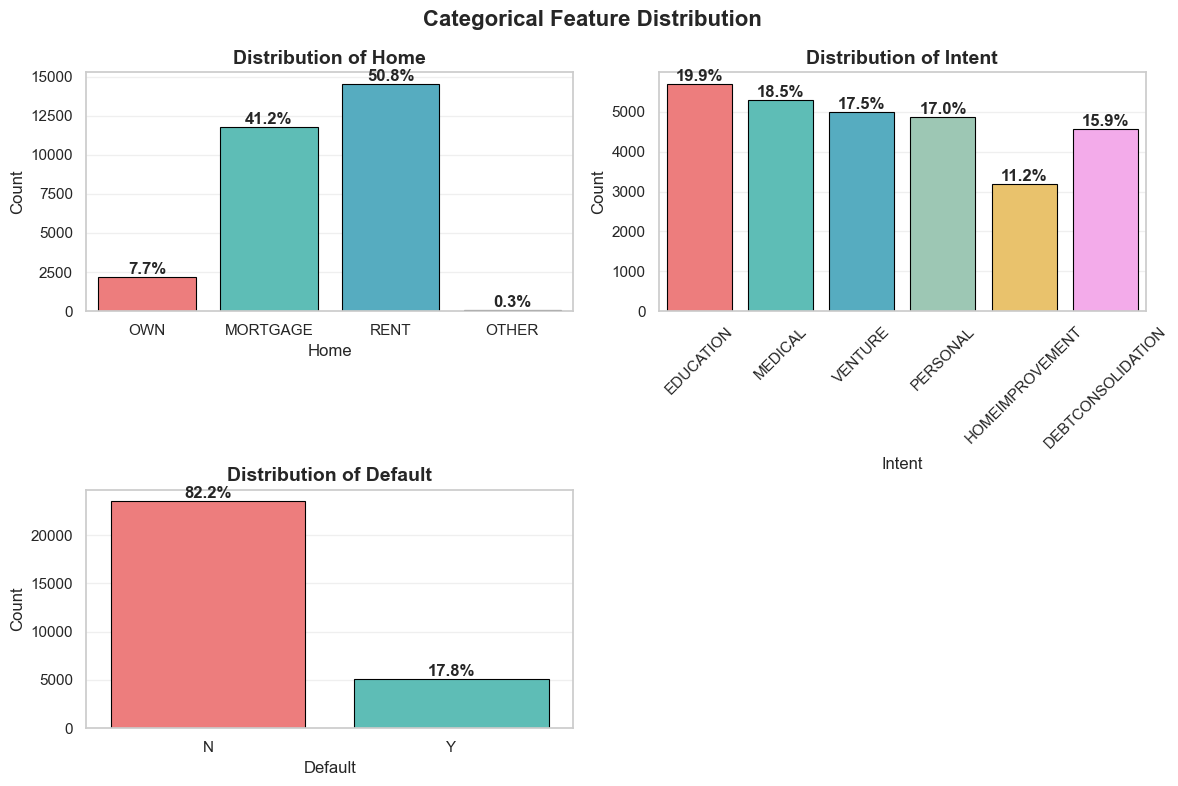

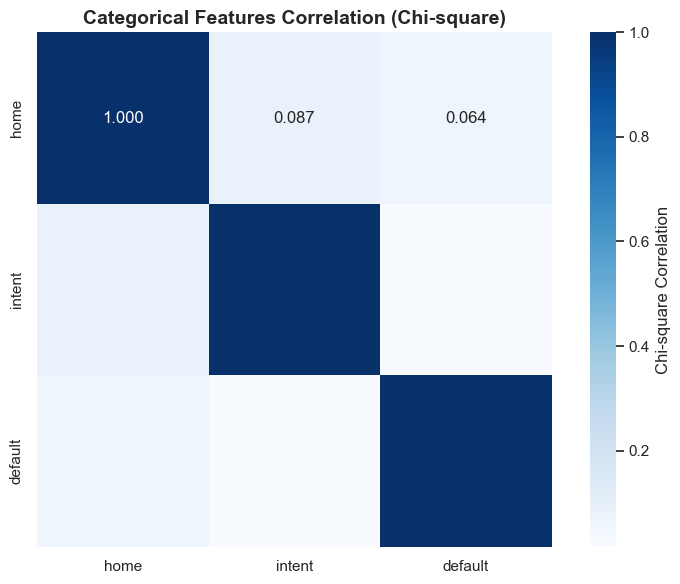

In [27]:
plot_categorical_distributions(df, cat_cols)

def chi2_correlation_heatmap(df, cat_cols):
    """Calculate and plot chi-square correlation between categorical features"""
    
    # Create correlation matrix
    n = len(cat_cols)
    corr_matrix = pd.DataFrame(np.zeros((n, n)), index=cat_cols, columns=cat_cols)
    
    # Calculate correlations
    for i, col1 in enumerate(cat_cols):
        for j, col2 in enumerate(cat_cols):
            if i == j:
                corr_matrix.loc[col1, col2] = 1.0
            else:
                # Create contingency table
                contingency = pd.crosstab(df[col1], df[col2])
                
                # Chi-square test
                chi2_stat, p_value, dof, expected = chi2_contingency(contingency)
                
                # Calculate Cramér's V
                n_obs = contingency.sum().sum()
                cramers_v = np.sqrt(chi2_stat / (n_obs * (min(contingency.shape) - 1)))
                
                corr_matrix.loc[col1, col2] = cramers_v
    
    # Plot heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(corr_matrix.astype(float), 
                annot=True, 
                fmt='.3f',
                cmap='Blues',
                square=True,
                cbar_kws={'label': 'Chi-square Correlation'})
    
    plt.title('Categorical Features Correlation (Chi-square)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return corr_matrix

correlation_matrix = chi2_correlation_heatmap(df, cat_cols)

## Categorical Features Correlation Summary

**Weak Associations**: All categorical variables show **very weak correlations** with each other (all values < 0.1), indicating they provide **independent information**.

**Modeling Implications**: The weak correlations suggest **no multicollinearity issues** among categorical features, making them suitable for inclusion in machine learning models without redundancy concerns.

### Correlation between Categorical and Numerical Features

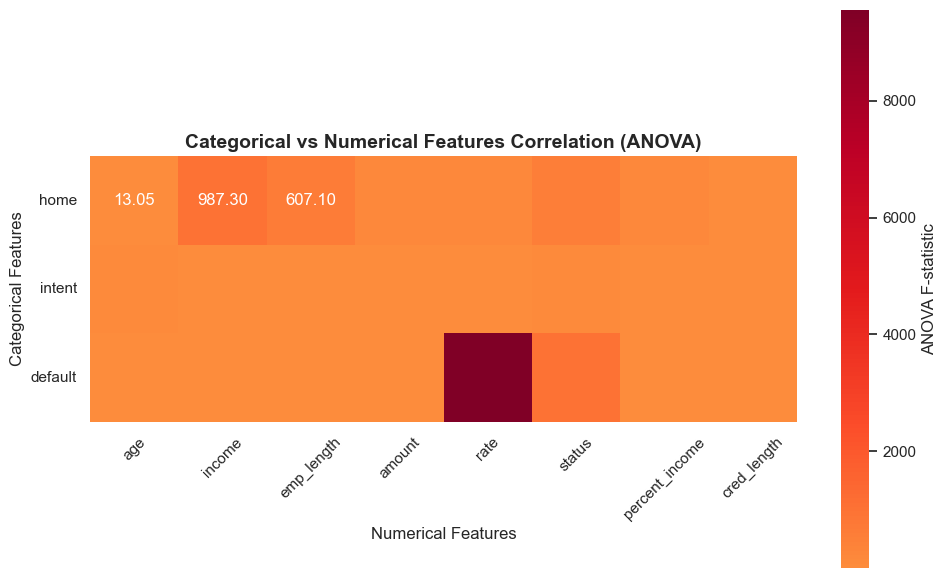

In [28]:
# ANOVA correlation between categorical and numerical features
def calculate_anova_correlation(df, cat_cols, num_cols):
    """Calculate ANOVA F-statistics between categorical and numerical features"""
    
    # Remove 'id' column if present
    num_cols_clean = [col for col in num_cols if col.lower() != 'id']
    
    anova_matrix = pd.DataFrame(index=cat_cols, columns=num_cols_clean)
    
    for cat_col in cat_cols:
        for num_col in num_cols_clean:
            try:
                # Remove missing values
                clean_df = df[[cat_col, num_col]].dropna()
                
                # Group numerical values by categorical levels
                groups = [group[num_col].values for name, group in clean_df.groupby(cat_col)]
                
                # Perform ANOVA
                f_stat, p_value = f_oneway(*groups)
                anova_matrix.loc[cat_col, num_col] = f_stat
                
            except Exception:
                anova_matrix.loc[cat_col, num_col] = 0
    
    return anova_matrix.astype(float)

def plot_anova_heatmap(df, cat_cols, num_cols):
    """Plot ANOVA correlation heatmap"""
    
    anova_matrix = calculate_anova_correlation(df, cat_cols, num_cols)
    
    plt.figure(figsize=(10, 6))
    
    sns.heatmap(anova_matrix, 
                annot=True, 
                fmt='.2f',
                cmap='YlOrRd',
                center=0,
                square=True,
                cbar_kws={'label': 'ANOVA F-statistic'})
    
    plt.title('Categorical vs Numerical Features Correlation (ANOVA)', 
              fontsize=14, fontweight='bold')
    plt.xlabel('Numerical Features', fontsize=12)
    plt.ylabel('Categorical Features', fontsize=12)
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    
    plt.tight_layout()
    plt.show()
    
    return anova_matrix


anova_results = plot_anova_heatmap(df, cat_cols, num_cols)

## Categorical vs Numerical Features Correlation (ANOVA)

**Strong Associations**: 
- **Default-Rate** shows the **highest F-statistic** (~4000+), indicating loan default status has a strong relationship with interest rates
- **Home** features show moderate associations with Income (987.30) and Employment Length (607.10)

**Weak Associations**: Most other categorical-numerical pairs show **low F-statistics** (< 1000), suggesting **minimal relationships** between housing/intent categories and most numerical variables.


## Numerical vs Numerical

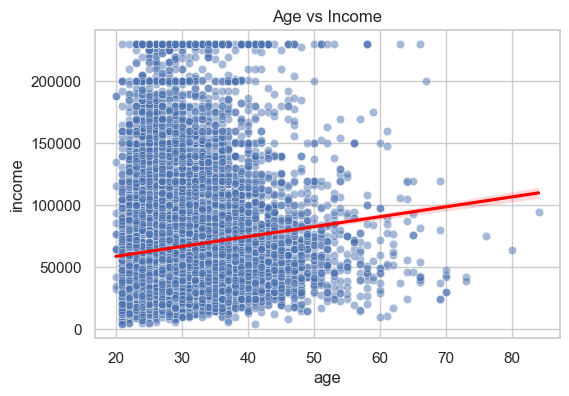

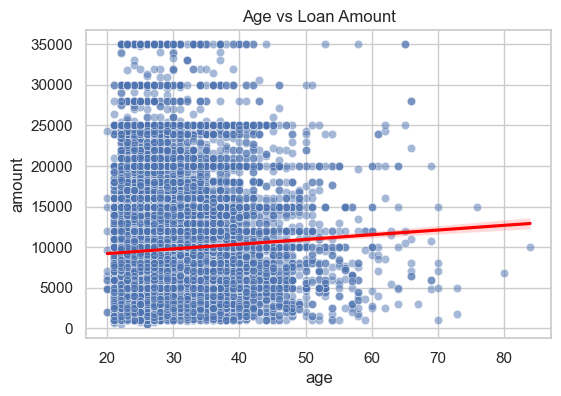

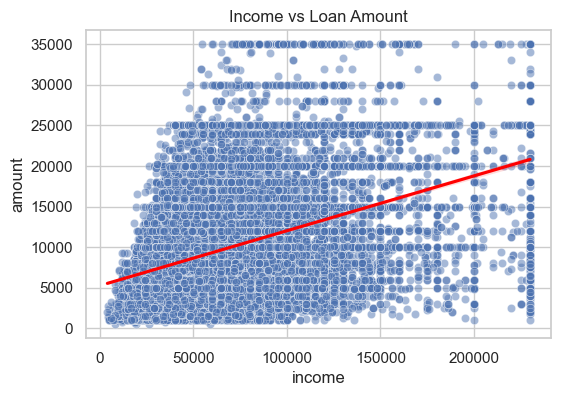

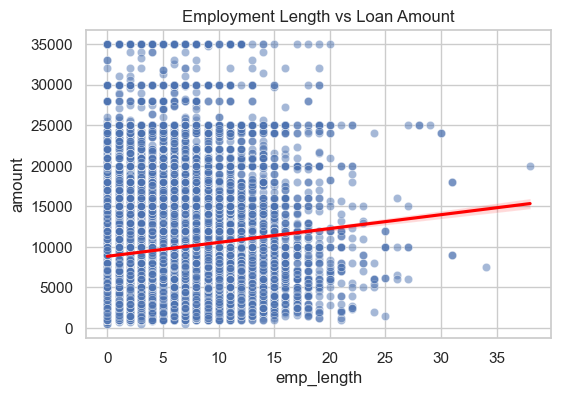

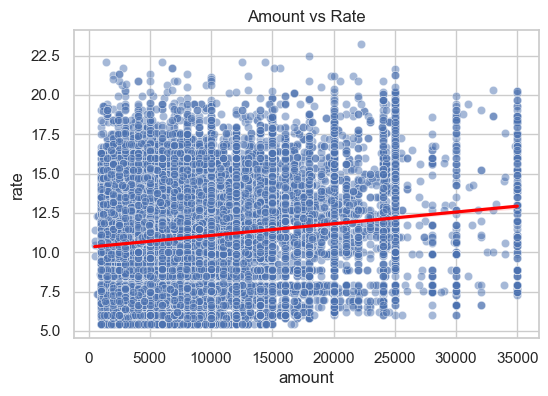

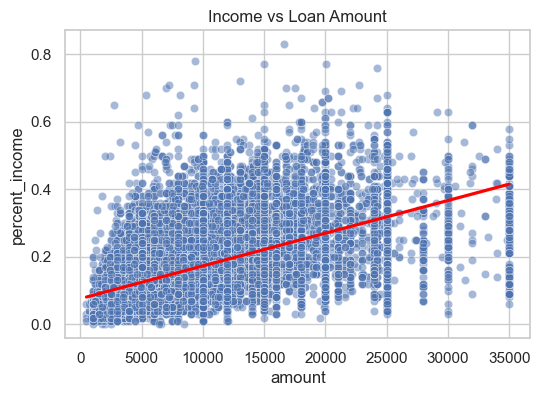

In [29]:
# Set plot style
sns.set(style="whitegrid")

# 1. Age vs Income (with  regression line)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='age', y='income', alpha=0.5)
sns.regplot(data=df, x='age', y='income', scatter=False, color='red')
plt.title('Age vs Income')
plt.show()

# 2. Age vs Amount (with  regression line)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='age', y='amount', alpha=0.5)
sns.regplot(data=df, x='age', y='amount', scatter=False, color='red')
plt.title('Age vs Loan Amount')
plt.show()

# 3. Income vs Amount (with  regression line)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='income', y='amount', alpha=0.5)
sns.regplot(data=df, x='income', y='amount', scatter=False, color='red')
plt.title('Income vs Loan Amount')
plt.show()

# 4. Emp_length vs Amount (with  regression line)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='emp_length', y='amount', alpha=0.5)
sns.regplot(data=df, x='emp_length', y='amount', scatter=False, color='red')
plt.title('Employment Length vs Loan Amount')
plt.show()

# 5. Amount vs Rate (with  regression line)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='amount', y='rate', alpha=0.5)
sns.regplot(data=df, x='amount', y='rate', scatter=False, color='red')
plt.title('Amount vs Rate')
plt.show()

# 3. Amount vs Percent_Income (with  regression line)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='amount', y='percent_income', alpha=0.5)
sns.regplot(data=df, x='amount', y='percent_income', scatter=False, color='red')
plt.title('Income vs Loan Amount')
plt.show()


## categorical vs categorical

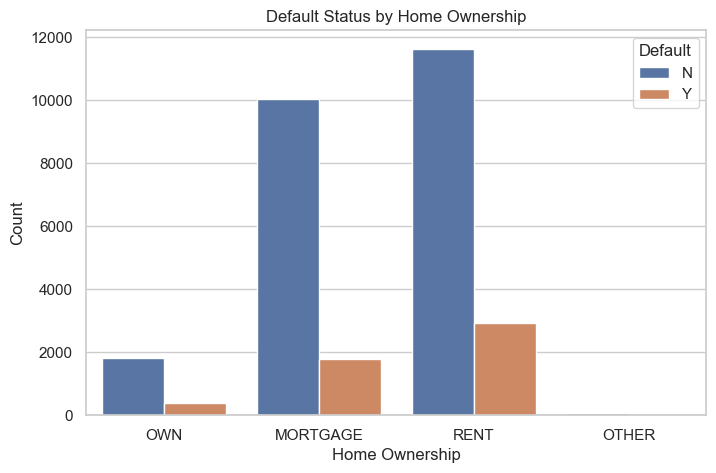

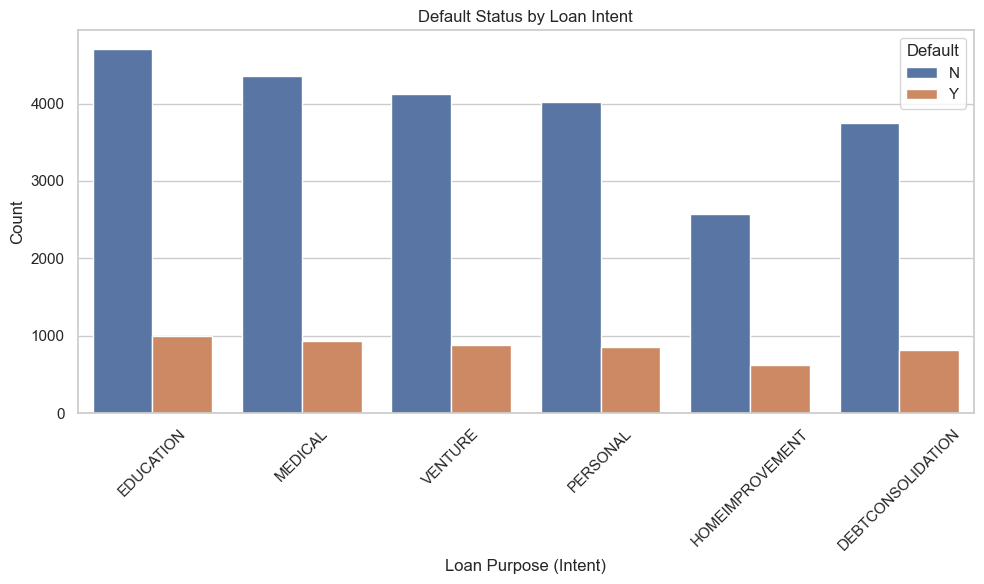

In [30]:
# Default Status by Home Ownership
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='home', hue='default')
plt.title('Default Status by Home Ownership')
plt.xlabel('Home Ownership')
plt.ylabel('Count')
plt.legend(title='Default')
plt.show()

# Default Status by Loan Intent
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='intent', hue='default')
plt.title('Default Status by Loan Intent')
plt.xlabel('Loan Purpose (Intent)')
plt.ylabel('Count')
plt.legend(title='Default')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## Categorical Vs Numerical

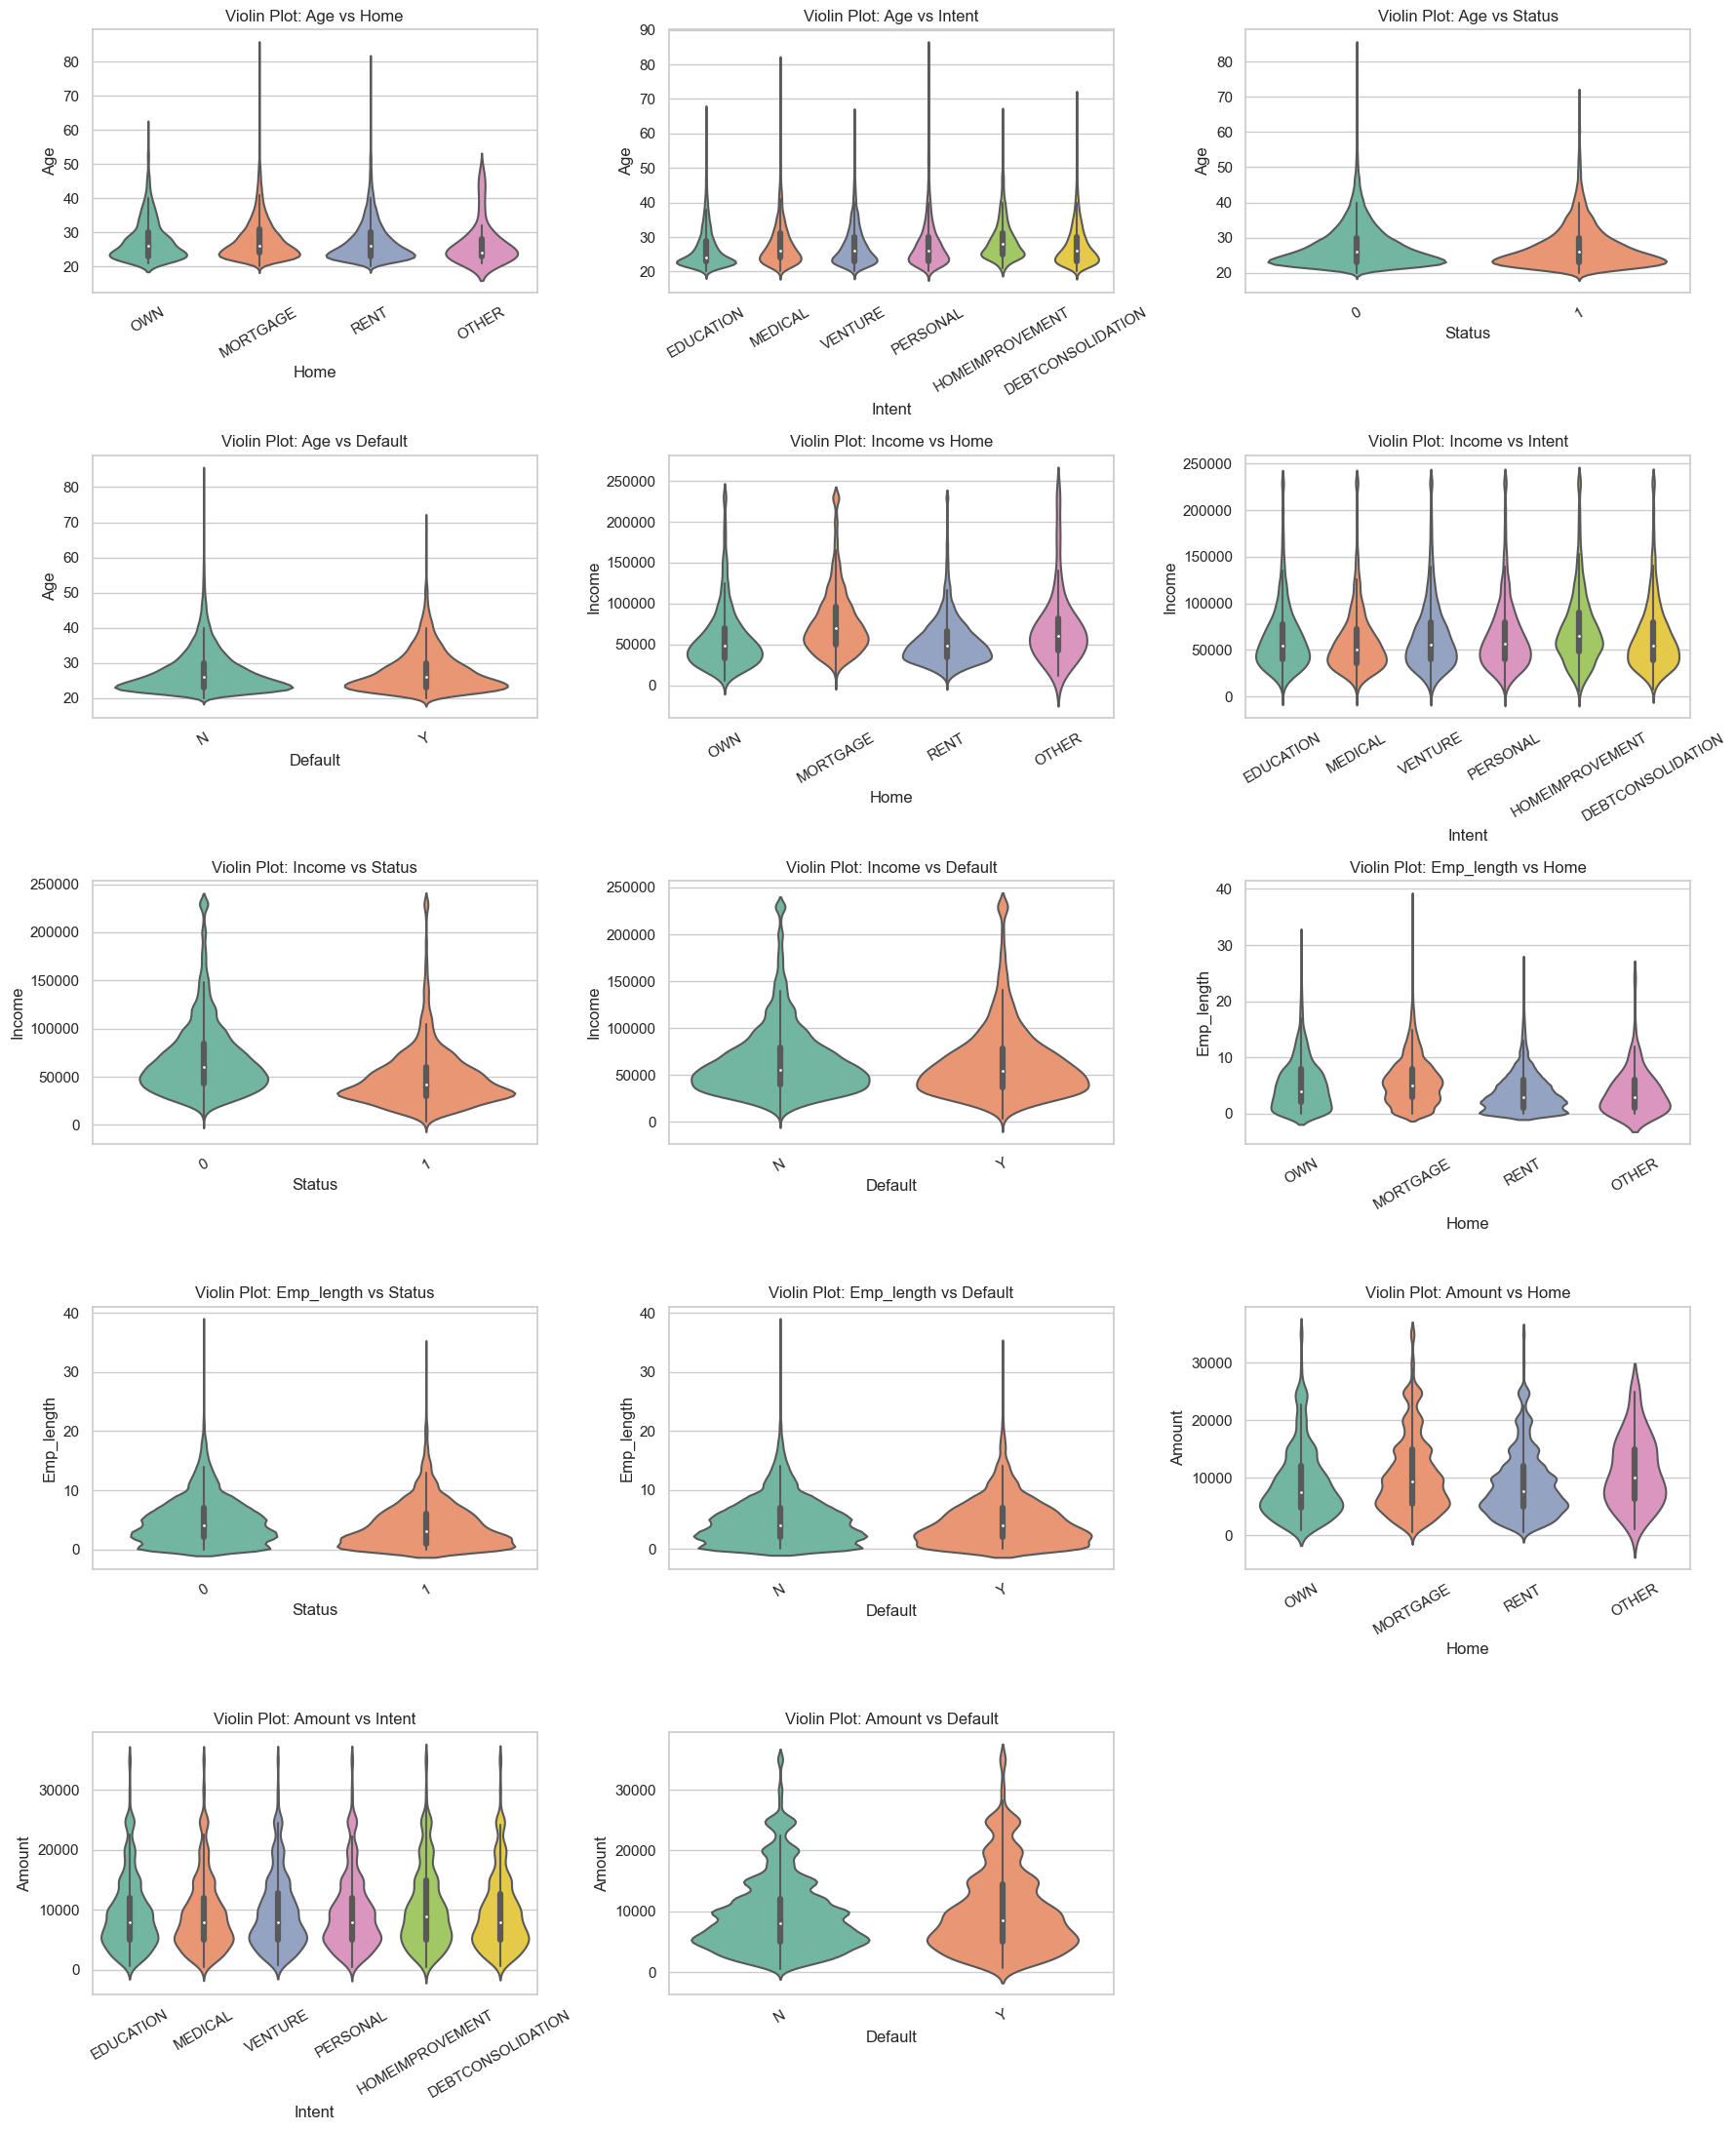

In [31]:
# Set up figure grid
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(18, 22))
axes = axes.flatten()

# Pairs of (categorical, numerical)
plots = [
    ('home', 'age'),
    ('intent', 'age'),
    ('status', 'age'),
    ('default', 'age'),
    ('home', 'income'),
    ('intent', 'income'),
    ('status', 'income'),
    ('default', 'income'),
    ('home', 'emp_length'),
    ('status', 'emp_length'),
    ('default', 'emp_length'),
    ('home', 'amount'),
    ('intent', 'amount'),
    ('default', 'amount'),
]

# Loop and create violin plots
for i, (cat, num) in enumerate(plots):
    sns.violinplot(data=df, x=cat, y=num, ax=axes[i], inner='box', palette='Set2')
    axes[i].set_title(f"Violin Plot: {num.capitalize()} vs {cat.capitalize()}", fontsize=12)
    axes[i].set_xlabel(cat.capitalize())
    axes[i].set_ylabel(num.capitalize())
    axes[i].tick_params(axis='x', rotation=30)

# Hide unused subplots if any
for j in range(len(plots), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


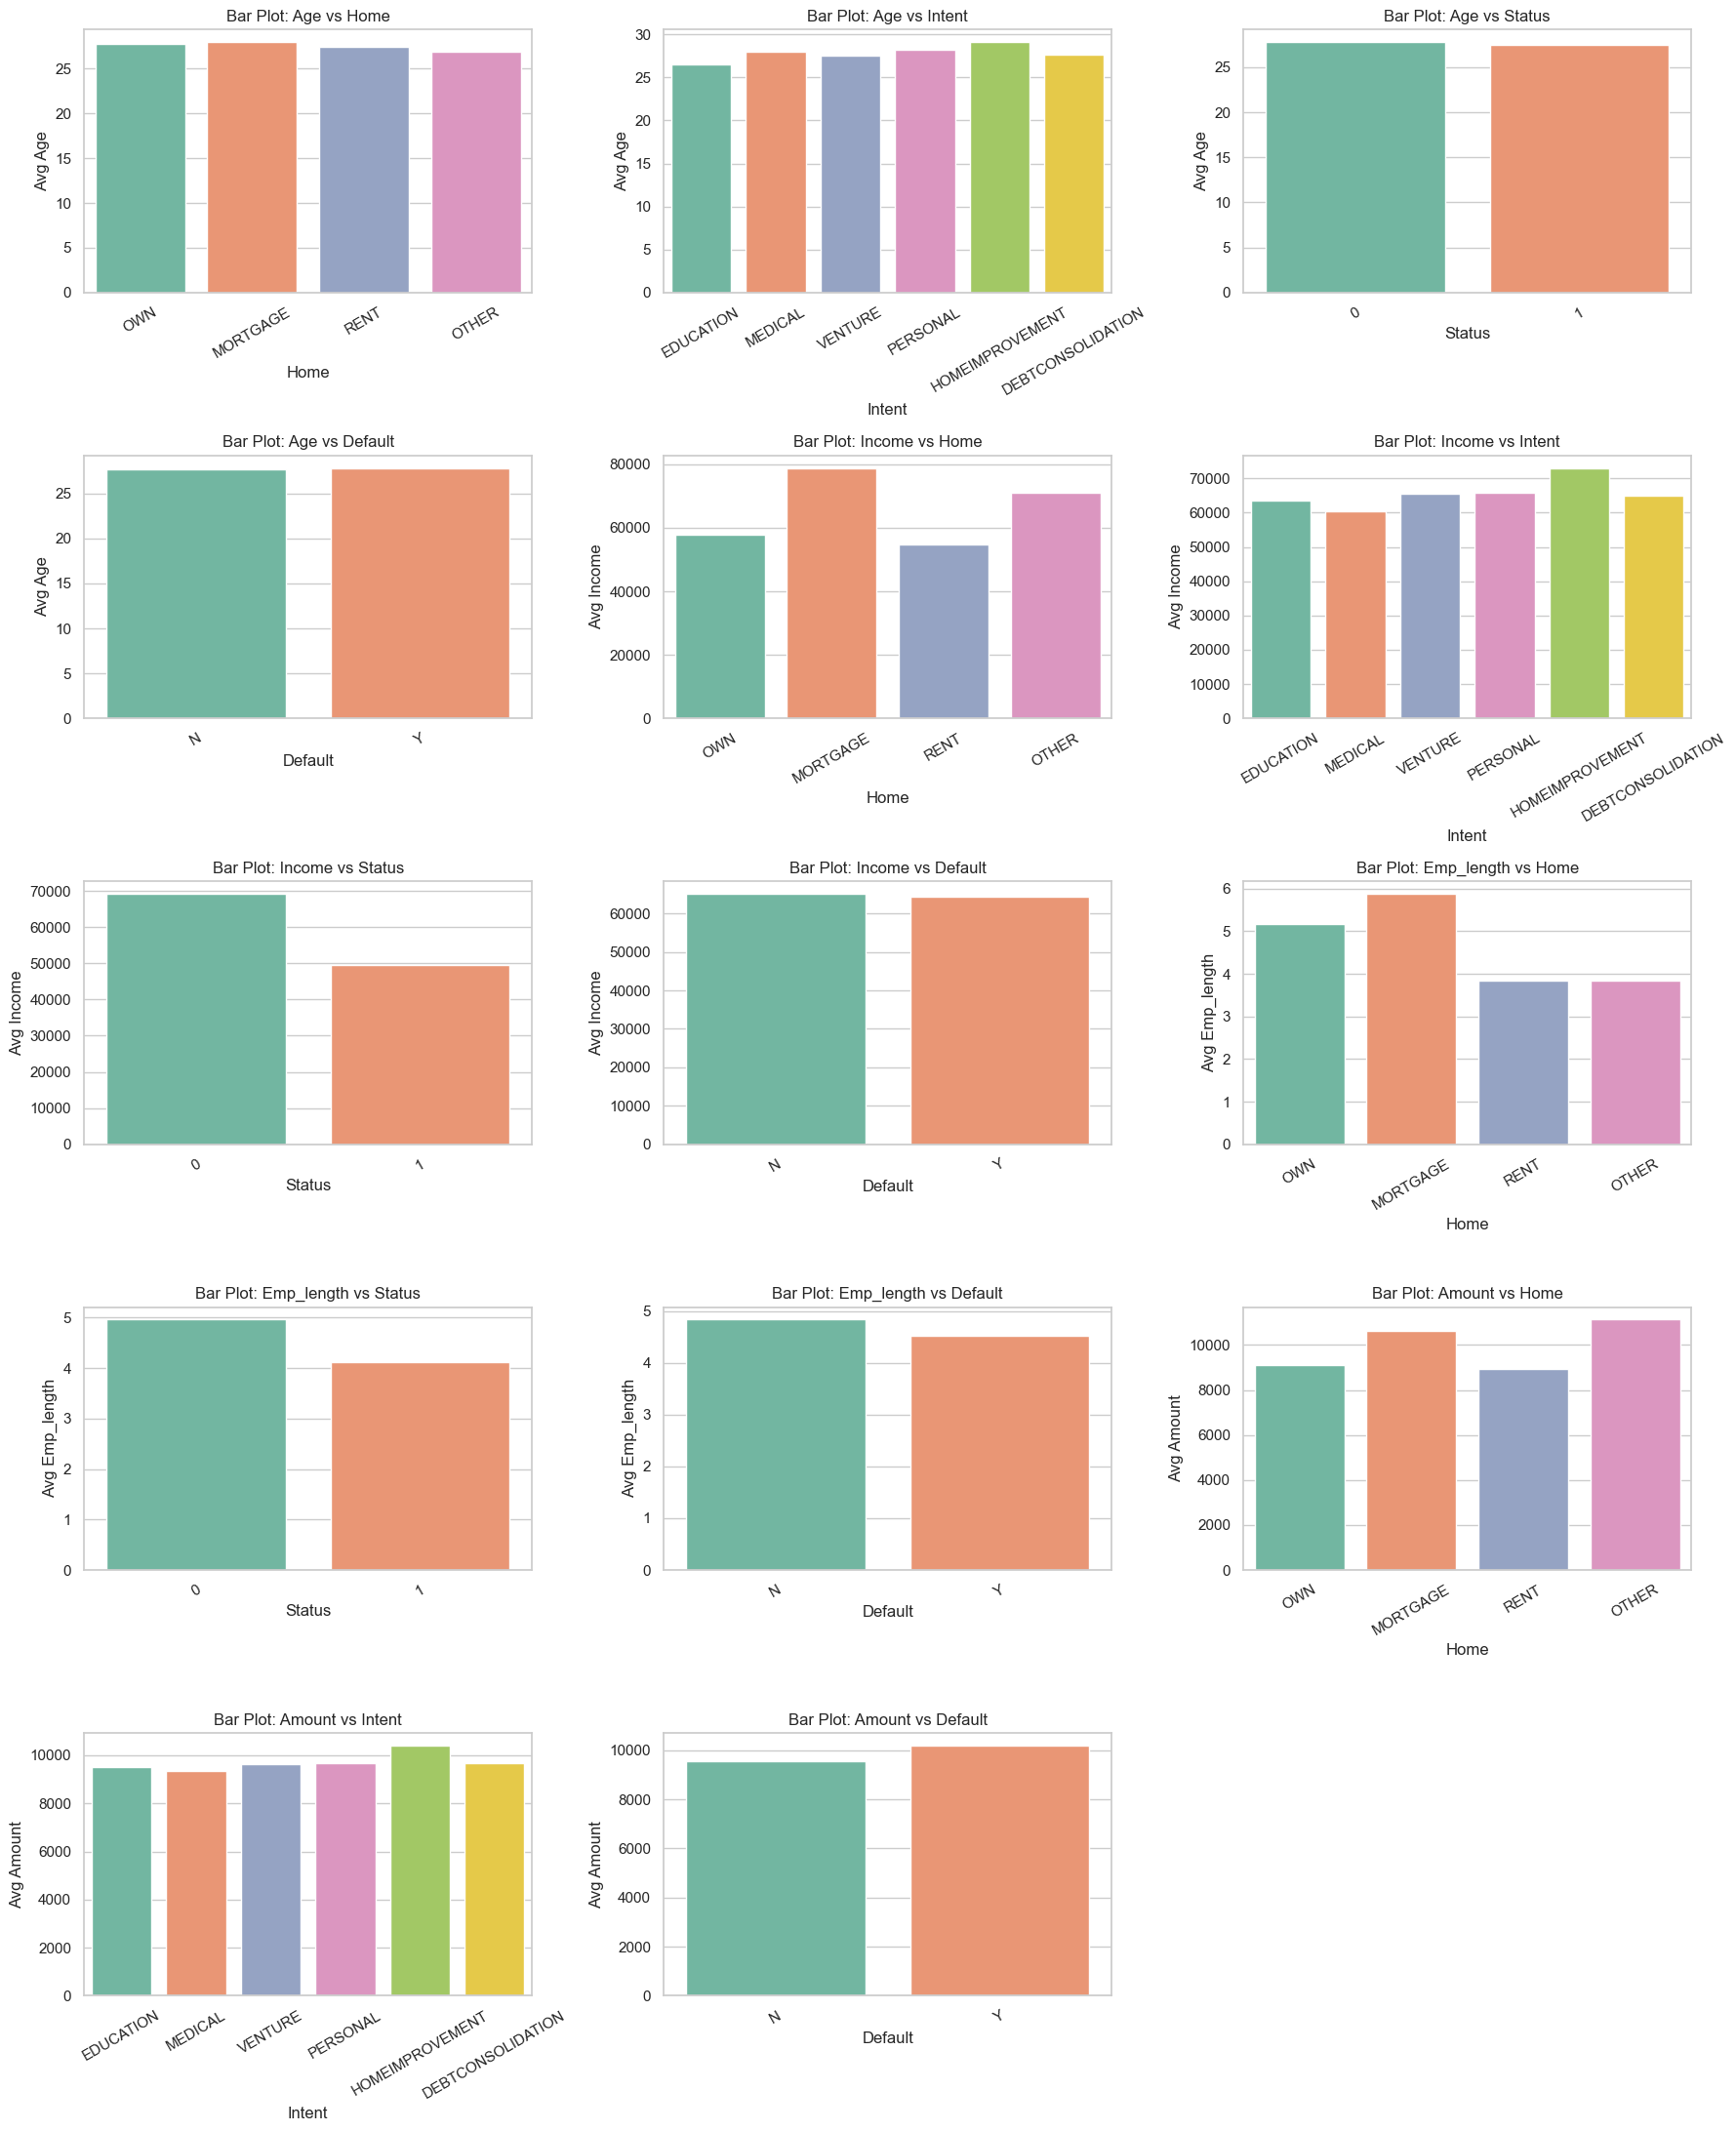

In [32]:
# Set up figure grid
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(18, 22))
axes = axes.flatten()

# Pairs of (categorical, numerical)
plots = [
    ('home', 'age'),
    ('intent', 'age'),
    ('status', 'age'),
    ('default', 'age'),
    ('home', 'income'),
    ('intent', 'income'),
    ('status', 'income'),
    ('default', 'income'),
    ('home', 'emp_length'),
    ('status', 'emp_length'),
    ('default', 'emp_length'),
    ('home', 'amount'),
    ('intent', 'amount'),
    ('default', 'amount'),
]

# Loop and create bar plots
for i, (cat, num) in enumerate(plots):
    sns.barplot(data=df, x=cat, y=num, ax=axes[i], estimator='mean', ci=None, palette='Set2')
    axes[i].set_title(f"Bar Plot: {num.capitalize()} vs {cat.capitalize()}", fontsize=12)
    axes[i].set_xlabel(cat.capitalize())
    axes[i].set_ylabel(f"Avg {num.capitalize()}")
    axes[i].tick_params(axis='x', rotation=30)

# Hide unused subplots if any
for j in range(len(plots), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


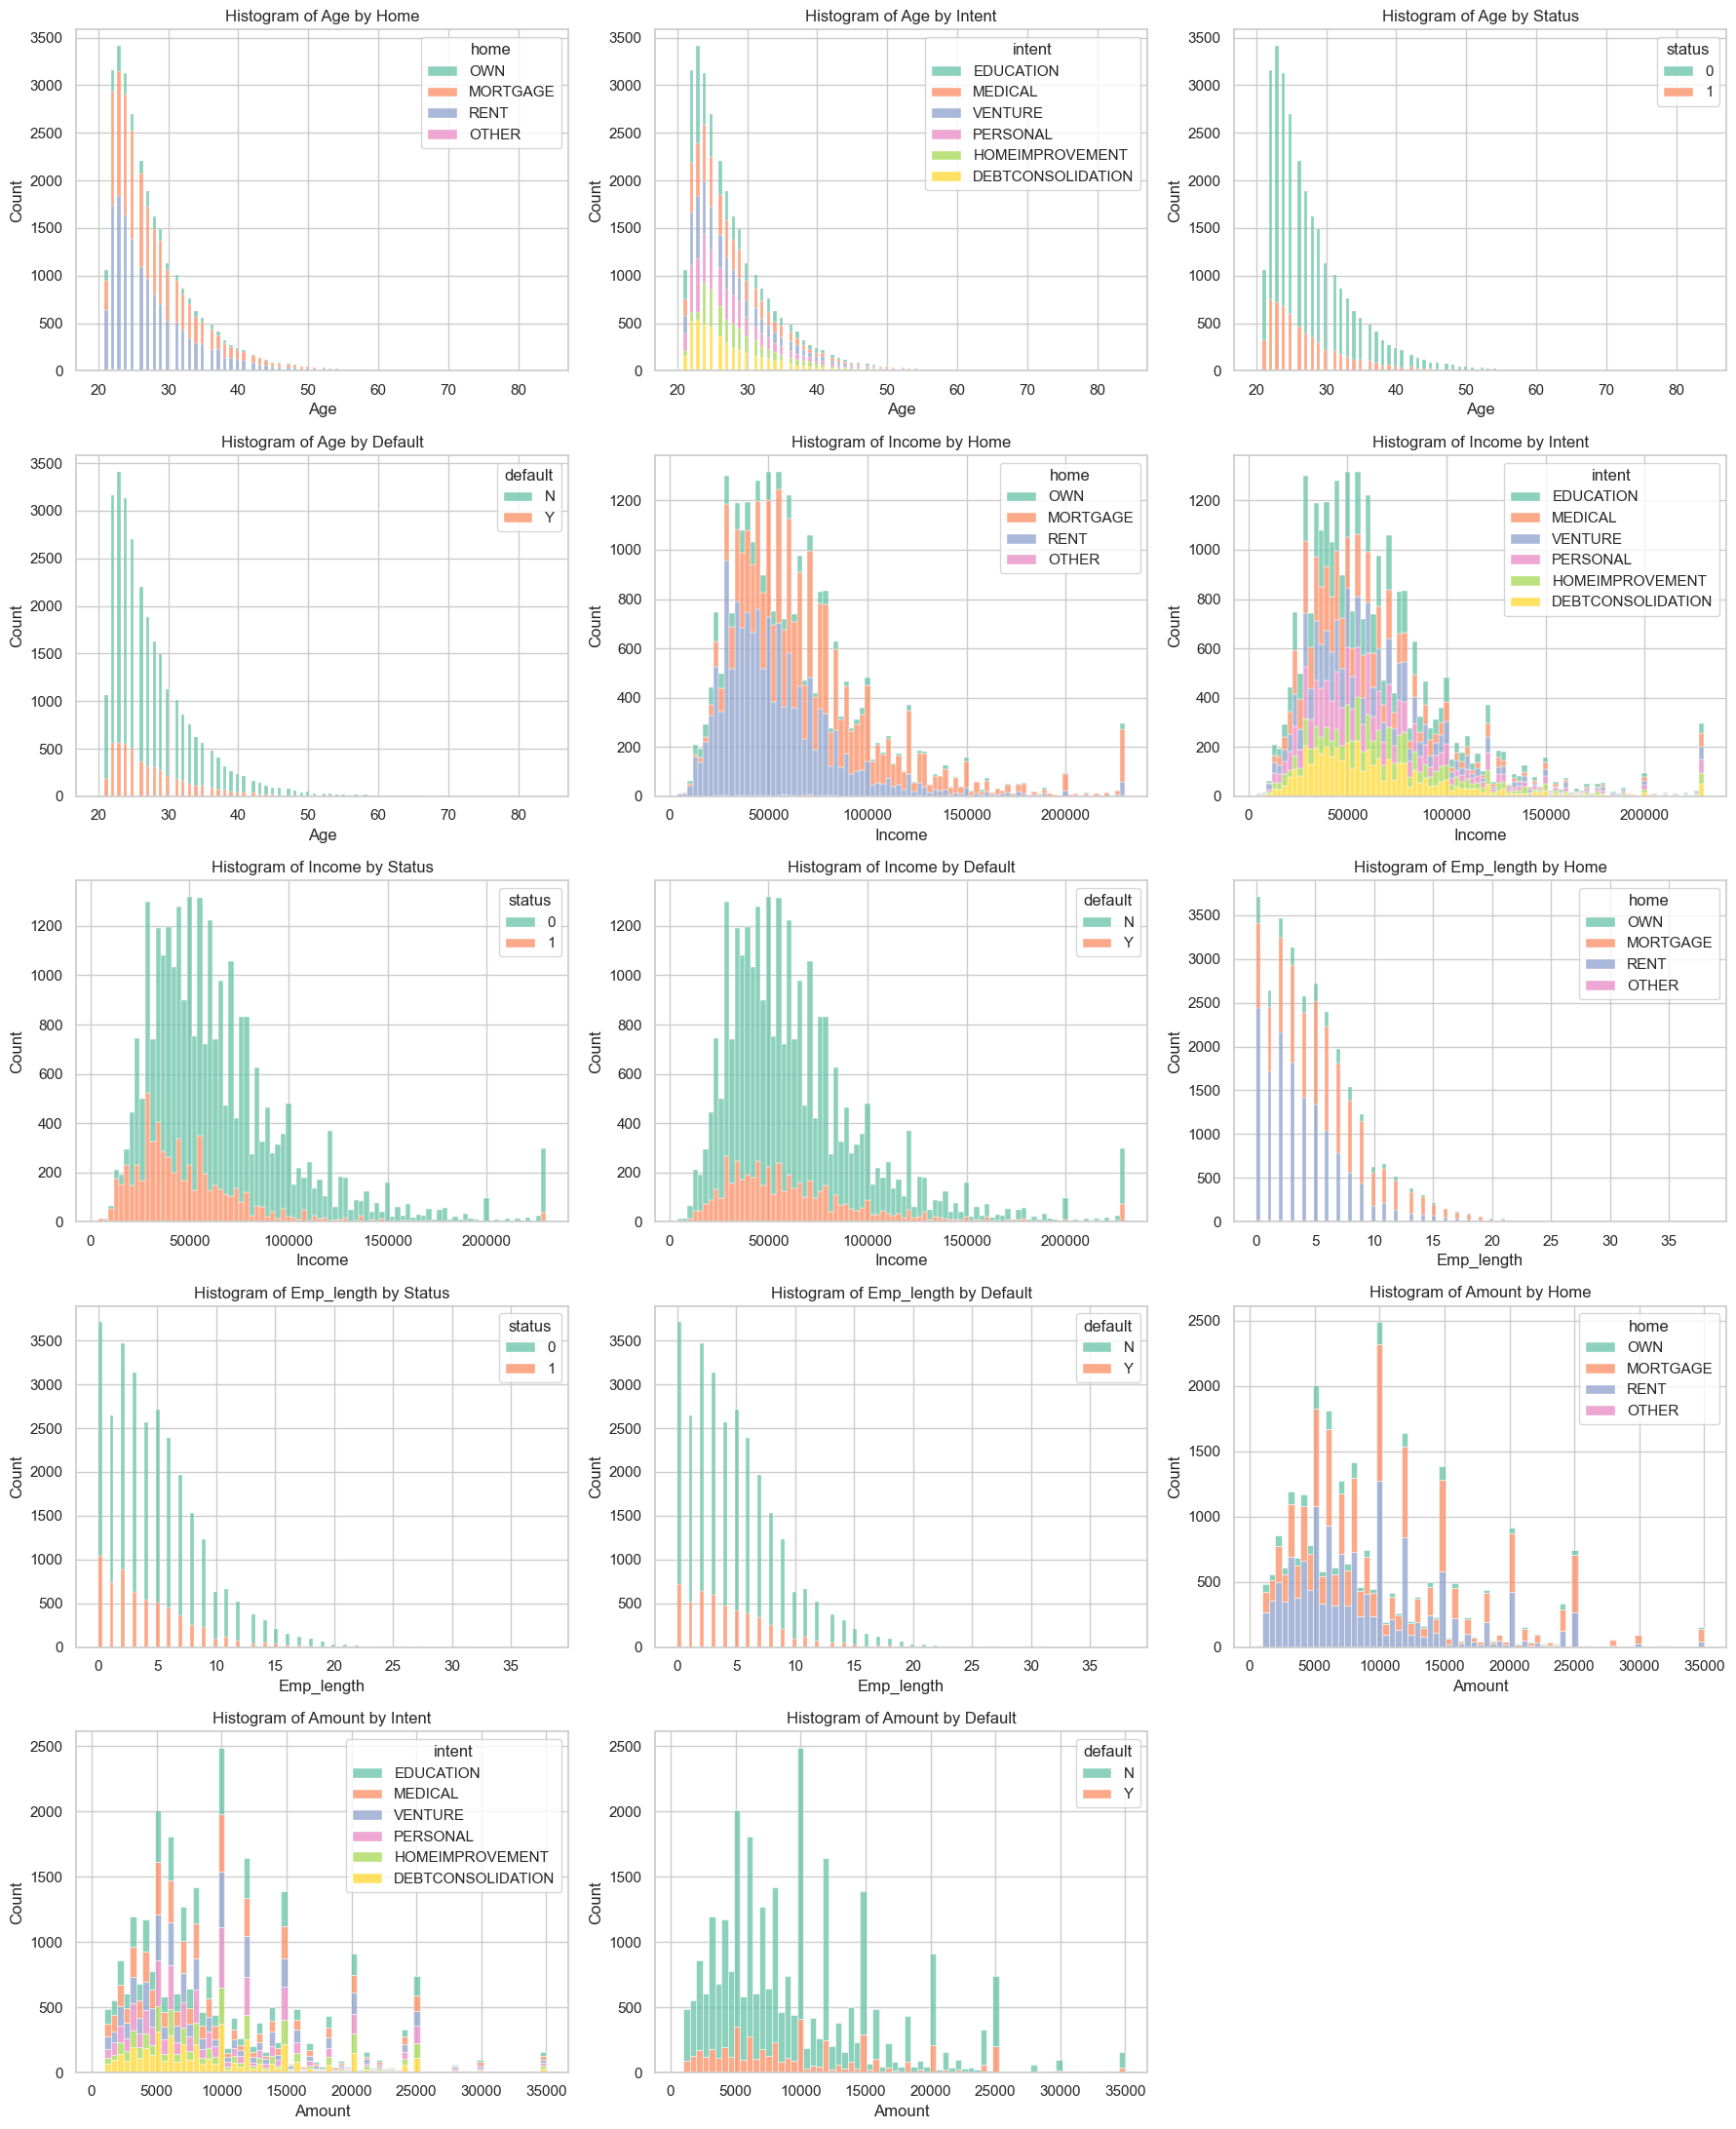

In [33]:
# Set up figure grid
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(18, 22))
axes = axes.flatten()

# Pairs of (categorical, numerical)
plots = [
    ('home', 'age'),
    ('intent', 'age'),
    ('status', 'age'),
    ('default', 'age'),
    ('home', 'income'),
    ('intent', 'income'),
    ('status', 'income'),
    ('default', 'income'),
    ('home', 'emp_length'),
    ('status', 'emp_length'),
    ('default', 'emp_length'),
    ('home', 'amount'),
    ('intent', 'amount'),
    ('default', 'amount'),
]

# Loop and create histograms per category
for i, (cat, num) in enumerate(plots):
    sns.histplot(data=df, x=num, hue=cat, ax=axes[i], multiple='stack', kde=False, palette='Set2')
    axes[i].set_title(f"Histogram of {num.capitalize()} by {cat.capitalize()}")
    axes[i].set_xlabel(num.capitalize())
    axes[i].set_ylabel("Count")

# Hide unused subplots if any
for j in range(len(plots), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


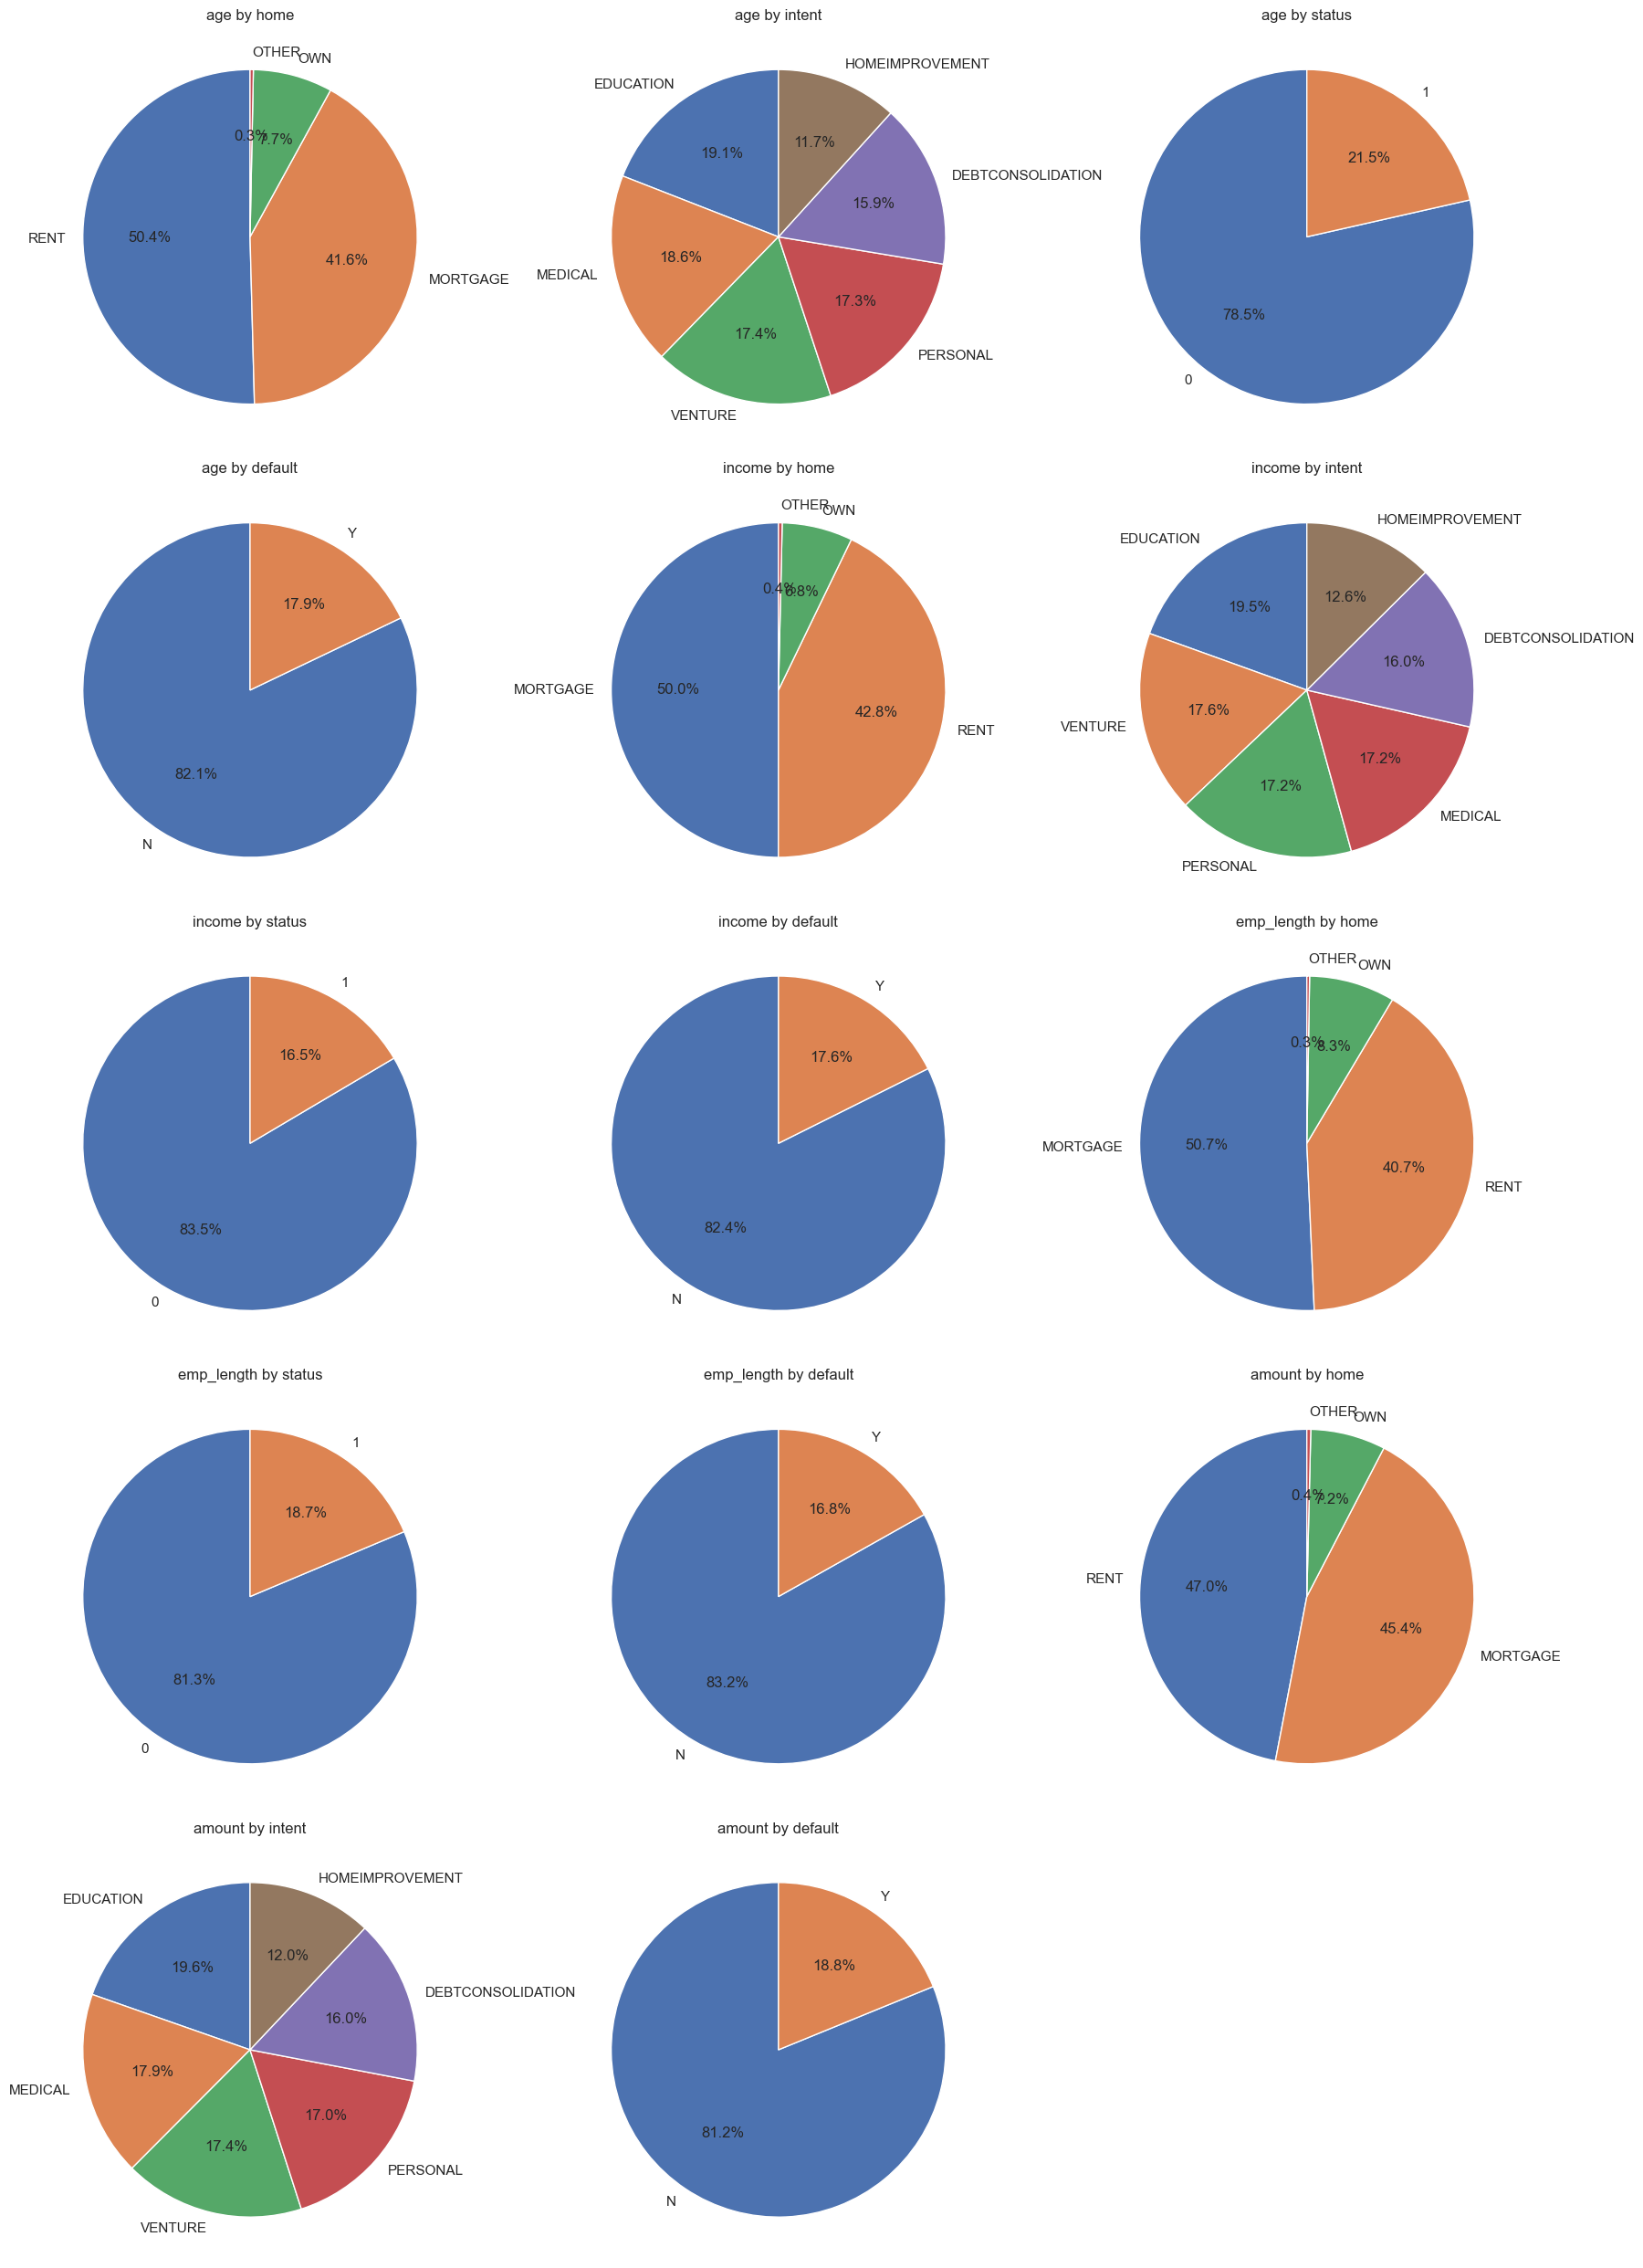

In [34]:
# List of (categorical, numerical) pairs to plot
pairs = [
    ('home', 'age'),
    ('intent', 'age'),
    ('status', 'age'),
    ('default', 'age'),
    ('home', 'income'),
    ('intent', 'income'),
    ('status', 'income'),
    ('default', 'income'),
    ('home', 'emp_length'),
    ('status', 'emp_length'),
    ('default', 'emp_length'),
    ('home', 'amount'),
    ('intent', 'amount'),
    ('default', 'amount'),
]

# Set up the subplot grid
ncols = 3
nrows = int(len(pairs) / ncols) + (len(pairs) % ncols > 0)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 25))
axes = axes.flatten()

# Create pie chart for each pair
for i, (cat, num) in enumerate(pairs):
    data = df.groupby(cat)[num].sum().sort_values(ascending=False)
    axes[i].pie(data, labels=data.index, autopct='%1.1f%%', startangle=90)
    axes[i].set_title(f"{num} by {cat}")

# Hide any unused subplots
for j in range(len(pairs), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()








### In this step, i prepare categorical variables for machine learning models
I use one_hot encoding for `home` and `intent` columns are  Nominal categories (no natural order) 

In [35]:
# Map 'default' column: 'y' → 0, 'n' → 1
df['default'] = df['default'].map({'Y': 0, 'N': 1})

# One-hot encode 'home' and 'intent' columns
df = pd.get_dummies(df, columns=['home', 'intent'], drop_first=True,dtype=int)

# Preview
print(df.head())


   age  income  emp_length  amount   rate  status  percent_income  default  \
1   21    9600         5.0    1000  11.14       0            0.10        1   
2   25    9600         1.0    5500  12.87       1            0.57        1   
3   23   65500         4.0   35000  15.23       1            0.53        1   
4   24   54400         8.0   35000  14.27       1            0.55        0   
5   21    9900         2.0    2500   7.14       1            0.25        1   

   cred_length  home_OTHER  home_OWN  home_RENT  intent_EDUCATION  \
1            2           0         1          0                 1   
2            3           0         0          0                 0   
3            2           0         0          1                 0   
4            4           0         0          1                 0   
5            2           0         1          0                 0   

   intent_HOMEIMPROVEMENT  intent_MEDICAL  intent_PERSONAL  intent_VENTURE  
1                       0              

### Feature Scaling Summary

| Feature         | Outliers? | Distribution Shape         | Recommended Scaler   |
|-----------------|-----------|-----------------------------|-----------------------|
| `age`           |  561    | Right-skewed, outliers      |  `RobustScaler`     |
| `income`        |  814    | Heavy right-skewed          |  `RobustScaler`     |
| `amount`        |  187    | Slight right-skewed         |  `RobustScaler`     |
| `emp_length`    |  194    | Right-skewed                |  `RobustScaler`     |
| `rate`          |  0      | Slightly uniform-ish        |  `StandardScaler`   |
| `status`        |  0      | Binary (0/1)                |  No scaling needed  |
| `percent_income`|  217    | Right-skewed, bounded [0–1] |  No scaling needed  |
| `cred_length`   |  233    | Slightly right-skewed       |  `RobustScaler`     |


I use the Same scaleing of train for val/test

In [36]:
# Define columns by scaler type
robust_cols = ['age', 'income', 'amount', 'emp_length', 'cred_length']
standard_cols = ['rate']

# Split data

train_df, temp_df = train_test_split(df, test_size=0.3, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

# Initialize Scalers

robust_scaler = RobustScaler()
standard_scaler = StandardScaler()

# Fit scalers ONLY on training data

robust_scaler.fit(train_df[robust_cols])
standard_scaler.fit(train_df[standard_cols])

# Apply transform (same scaler for val/test)

def scale_dataframe(df_split):
    df_scaled = df_split.copy()
    df_scaled[robust_cols] = robust_scaler.transform(df_scaled[robust_cols])
    df_scaled[standard_cols] = standard_scaler.transform(df_scaled[standard_cols])
    return df_scaled

train_scaled = scale_dataframe(train_df)
val_scaled = scale_dataframe(val_df)
test_scaled = scale_dataframe(test_df)

# Final check

print("Scaling complete.")
print("Scaled columns:", robust_cols + standard_cols)

# Preview:
train_scaled.head()


Scaling complete.
Scaled columns: ['age', 'income', 'amount', 'emp_length', 'cred_length', 'rate']


,age,income,emp_length,amount,rate,status,percent_income,default,cred_length,home_OTHER,home_OWN,home_RENT,intent_EDUCATION,intent_HOMEIMPROVEMENT,intent_MEDICAL,intent_PERSONAL,intent_VENTURE
12262,-0.428571,1.041951,-0.8,0.266667,0.022392,0,0.10,1,0.0,0,0,0,1,0,0,0,0
6888,-0.571429,-0.016585,-0.6,0.266667,-0.024043,0,0.18,1,-0.2,0,1,0,0,0,0,0,1
23820,0.428571,0.300488,0.0,-0.853333,0.127644,0,0.02,1,1.2,0,0,1,1,0,0,0,0
16202,0.142857,-0.831220,1.4,-0.533333,-0.138582,0,0.19,1,1.0,0,1,0,0,1,0,0,0
21586,0.428571,0.455610,0.6,0.096667,-1.571868,0,0.12,1,0.6,0,1,0,0,0,1,0,0


### Random Forest Model Training and Evaluation

In this section:

1. I **separated the features and the target variable** (`default`) from the scaled training, validation, and test datasets.
2. I **trained a Random Forest Classifier** using the training set.
3. I **predicted outcomes** on the validation and test sets.
4. I **evaluated performance** using:
   - Accuracy Score
   - Confusion Matrix
   - Classification Report (Precision, Recall, F1-Score)
5. I **compared validation vs. test results** to check for overfitting or underfitting.

---

###  Why Random Forest?

Random Forest is a powerful ensemble model that:

- Handles both numerical and categorical features well.
- Is **robust to outliers and noise** (important for our data).
- Reduces overfitting by combining results from multiple decision trees.
- Requires minimal preprocessing (no need for scaling, although I scaled for consistency across models).
- Provides **feature importance**, helping with model interpretability.

It's a strong baseline model before exploring more complex algorithms like XGBoost.

In [37]:
# 1. Separate Features and Target
X_train = train_scaled.drop(columns='default')
y_train = train_scaled['default']

X_val = val_scaled.drop(columns='default')
y_val = val_scaled['default']

X_test = test_scaled.drop(columns='default')
y_test = test_scaled['default']

# 2. Initialize and Train Random Forest
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# 3. Predict on Validation and Test Sets
val_preds = rf_model.predict(X_val)
test_preds = rf_model.predict(X_test)

# 4. Evaluate Performance
val_accuracy = accuracy_score(y_val, val_preds)
test_accuracy = accuracy_score(y_test, test_preds)

val_conf_matrix = confusion_matrix(y_val, val_preds)
test_conf_matrix = confusion_matrix(y_test, test_preds)

# 5. Display Results
print("Random Forest Results")
print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

print("\nConfusion Matrix (Validation):\n", val_conf_matrix)
print("\nConfusion Matrix (Test):\n", test_conf_matrix)

# Classification report on validation set
print("Classification Report - Validation Set")
print(classification_report(y_val, val_preds))

# Classification report on test set
print("Classification Report - Test Set")
print(classification_report(y_test, test_preds))



Random Forest Results
Validation Accuracy: 83.4 %
Test Accuracy: 83.73 %

Confusion Matrix (Validation):
 [[ 342  397]
 [ 316 3240]]

Confusion Matrix (Test):
 [[ 371  383]
 [ 316 3225]]
Classification Report - Validation Set
              precision    recall  f1-score   support

           0       0.52      0.46      0.49       739
           1       0.89      0.91      0.90      3556

    accuracy                           0.83      4295
   macro avg       0.71      0.69      0.70      4295
weighted avg       0.83      0.83      0.83      4295

Classification Report - Test Set
              precision    recall  f1-score   support

           0       0.54      0.49      0.51       754
           1       0.89      0.91      0.90      3541

    accuracy                           0.84      4295
   macro avg       0.72      0.70      0.71      4295
weighted avg       0.83      0.84      0.83      4295



### Feature Importance (Random Forest)

In this step, we visualize the **importance of each feature** based on the trained Random Forest model.

- Feature importance shows how much each feature contributes to the model's decisions.
- Features are sorted from most to least important.
- This helps us understand which inputs have the most impact on predicting loan default.


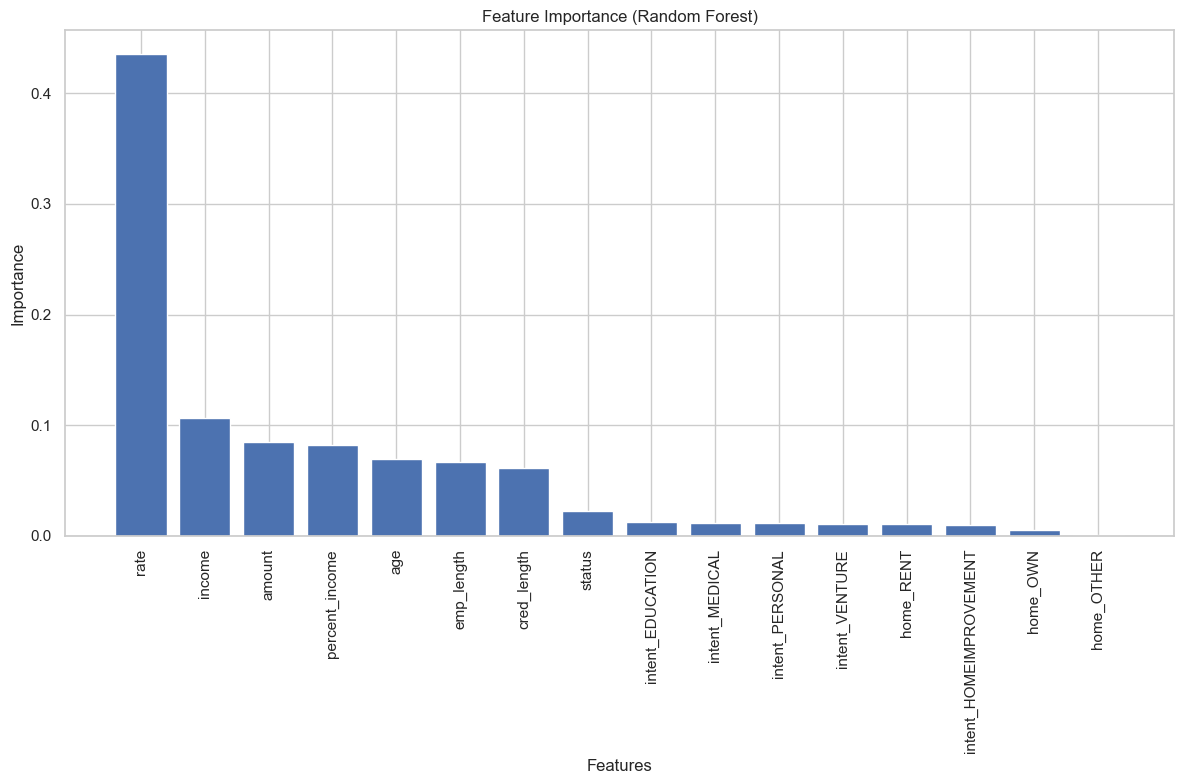

In [38]:
# Get feature importances from trained model
importances = rf_model.feature_importances_

# Get feature names
feature_names = X_train.columns

# Sort features by importance
sorted_idx = np.argsort(importances)[::-1]

# Plot
plt.figure(figsize=(12, 8))
plt.bar(range(len(importances)), importances[sorted_idx])
plt.xticks(range(len(importances)), feature_names[sorted_idx], rotation=90)
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

### Permutation Feature Importance

This plot shows how important each feature is by measuring the **drop in model accuracy** when its values are randomly shuffled.

- A larger drop in accuracy means the feature is more important.
- Helps in identifying which features the model relies on most.
- Calculated using the **validation set** to avoid overfitting.


In [39]:
# Apply permutation importance on validation set
result = permutation_importance(
    rf_model, X_val, y_val,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)


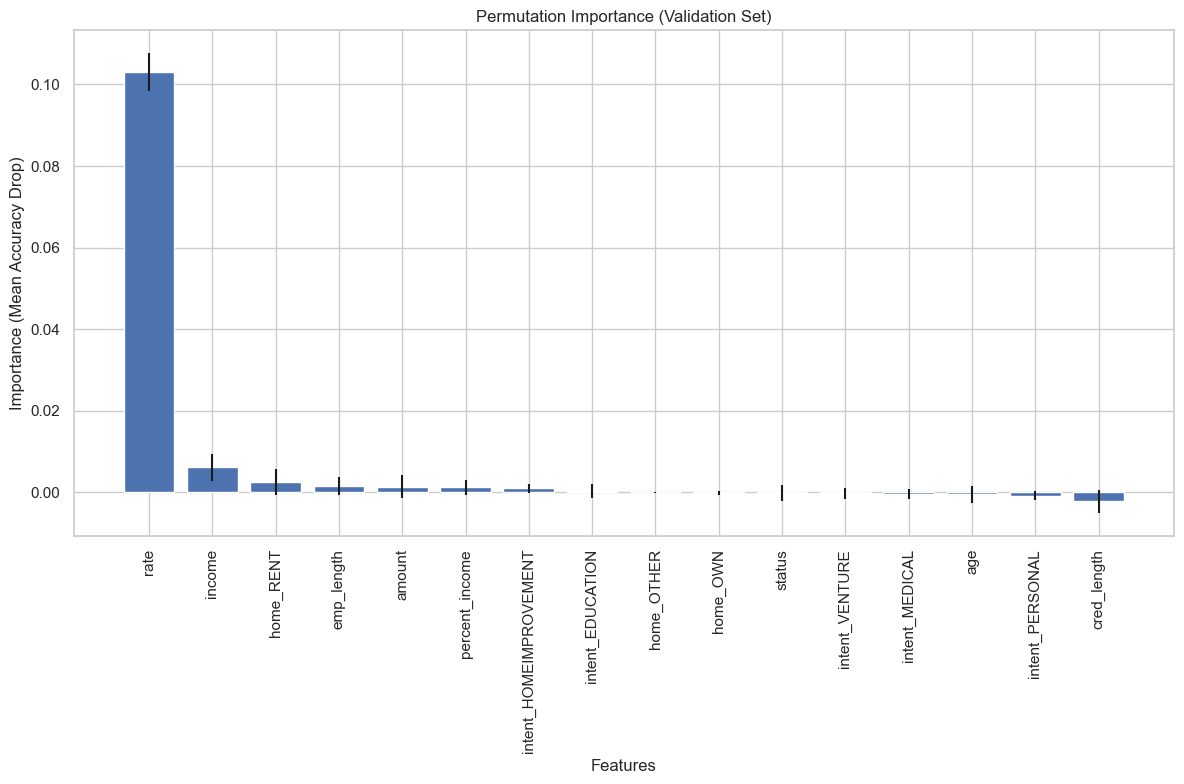

In [40]:
# Extract importances and sort
importances = result.importances_mean
std = result.importances_std
indices = np.argsort(importances)[::-1]

# Feature names
features = X_val.columns

# Plot
plt.figure(figsize=(12, 8))
plt.bar(range(len(importances)), importances[indices], yerr=std[indices])
plt.xticks(range(len(importances)), features[indices], rotation=90)
plt.title("Permutation Importance (Validation Set)")
plt.xlabel("Features")
plt.ylabel("Importance (Mean Accuracy Drop)")
plt.tight_layout()
plt.show()


### Recursive Feature Elimination with Cross-Validation (RFECV)

In this step, we used **RFECV** (Recursive Feature Elimination with Cross-Validation) to automatically find the **optimal number of features** for the model:

- A **Random Forest Classifier** was used as the base estimator.
- **Stratified K-Fold Cross-Validation** ensures balanced class distribution during feature selection.
- RFECV eliminates the least important features and evaluates performance using cross-validation.
- The goal is to keep only the most useful features that improve model accuracy.

This helps reduce overfitting and speeds up training by removing irrelevant features.


In [41]:
# Features & target
X_train = train_scaled.drop(columns=['default'])
y_train = train_scaled['default']

# Initialize model
rf_model = RandomForestClassifier(random_state=42)

# Cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# RFECV: Automatically selects best number of features
rfecv = RFECV(estimator=rf_model, cv=cv, scoring='accuracy', n_jobs=-1)

# Fit to training data
rfecv.fit(X_train, y_train)

# Selected features
selected_features = X_train.columns[rfecv.support_]

print("Optimal number of features:", rfecv.n_features_)
print("Selected Features:")
print(selected_features.tolist())

# Optional: View feature rankings
ranking_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Ranking': rfecv.ranking_,
    'Selected': rfecv.support_
}).sort_values(by='Ranking')

print("\n Feature Rankings:")
print(ranking_df)


Optimal number of features: 6
Selected Features:
['age', 'income', 'amount', 'rate', 'percent_income', 'cred_length']

 Feature Rankings:
                   Feature  Ranking  Selected
0                      age        1      True
1                   income        1      True
3                   amount        1      True
4                     rate        1      True
6           percent_income        1      True
7              cred_length        1      True
2               emp_length        2     False
5                   status        3     False
11        intent_EDUCATION        4     False
15          intent_VENTURE        5     False
10               home_RENT        6     False
13          intent_MEDICAL        7     False
14         intent_PERSONAL        8     False
12  intent_HOMEIMPROVEMENT        9     False
9                 home_OWN       10     False
8               home_OTHER       11     False


### Apply model with the most imprtant features onlt

In [42]:
# Select features using the RFECV support mask
selected_features = X_train.columns[rfecv.support_]

# Apply to all sets
X_train_selected = X_train[selected_features]
X_val_selected = val_scaled[selected_features]
X_test_selected = test_scaled[selected_features]

y_val = val_scaled['default']
y_test = test_scaled['default']

# Preview
print("Final selected features applied to all sets:")
print(list(selected_features))
print("\n Shapes:")
print("Train:", X_train_selected.shape)
print("Validation:", X_val_selected.shape)
print("Test:", X_test_selected.shape)


Final selected features applied to all sets:
['age', 'income', 'amount', 'rate', 'percent_income', 'cred_length']

 Shapes:
Train: (20041, 6)
Validation: (4295, 6)
Test: (4295, 6)


In [43]:
# Fit the model with selected features
rf_selected = RandomForestClassifier(random_state=42)
rf_selected.fit(X_train_selected, y_train)

# Predict on validation and test sets
y_val_pred = rf_selected.predict(X_val_selected)
y_test_pred = rf_selected.predict(X_test_selected)

# Accuracy scores
val_acc = accuracy_score(y_val, y_val_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Validation Accuracy (selected features): {val_acc:.4f}")
print(f"Test Accuracy (selected features): {test_acc:.4f}")

# Classification report
print("\n Validation Classification Report:")
print(classification_report(y_val, y_val_pred))

print("\n Test Classification Report:")
print(classification_report(y_test, y_test_pred))


Validation Accuracy (selected features): 0.8324
Test Accuracy (selected features): 0.8263

 Validation Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.48      0.50       739
           1       0.89      0.91      0.90      3556

    accuracy                           0.83      4295
   macro avg       0.70      0.69      0.70      4295
weighted avg       0.83      0.83      0.83      4295


 Test Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.47      0.48       754
           1       0.89      0.90      0.90      3541

    accuracy                           0.83      4295
   macro avg       0.70      0.68      0.69      4295
weighted avg       0.82      0.83      0.82      4295



### Feature Extraction using Linear Discriminant Analysis (LDA)

In this step, we applied **Linear Discriminant Analysis (LDA)** for **dimensionality reduction** after selecting the best features:

- LDA transforms the selected features into a lower-dimensional space (here, 1 component for binary classification).
- This technique captures the **maximum class separability**, improving model focus on relevant patterns.
- We then trained a **Random Forest** on the LDA-transformed data.
- Finally, we evaluated the model's performance on both **validation** and **test** sets.

LDA helps simplify the feature space while preserving class-discriminative information.

In [44]:
# Prepare data
X_train_sel = train_scaled[selected_features]
X_val_sel = val_scaled[selected_features]
X_test_sel = test_scaled[selected_features]

y_train = train_scaled['default']
y_val = val_scaled['default']
y_test = test_scaled['default']

# Apply LDA
lda = LDA(n_components=1)  # For binary classification, max is 1
X_train_lda = lda.fit_transform(X_train_sel, y_train)
X_val_lda = lda.transform(X_val_sel)
X_test_lda = lda.transform(X_test_sel)

# Fit Random Forest on LDA-transformed data
rf_lda = RandomForestClassifier(random_state=42)
rf_lda.fit(X_train_lda, y_train)

# Evaluate on Validation Set
print("Validation Set Performance (LDA):")
y_val_pred = rf_lda.predict(X_val_lda)
print(classification_report(y_val, y_val_pred))

# Evaluate on Test Set
print("Test Set Performance (LDA):")
y_test_pred = rf_lda.predict(X_test_lda)
print(classification_report(y_test, y_test_pred))


Validation Set Performance (LDA):
              precision    recall  f1-score   support

           0       0.47      0.48      0.48       739
           1       0.89      0.89      0.89      3556

    accuracy                           0.82      4295
   macro avg       0.68      0.68      0.68      4295
weighted avg       0.82      0.82      0.82      4295

Test Set Performance (LDA):
              precision    recall  f1-score   support

           0       0.49      0.49      0.49       754
           1       0.89      0.89      0.89      3541

    accuracy                           0.82      4295
   macro avg       0.69      0.69      0.69      4295
weighted avg       0.82      0.82      0.82      4295

